<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-15/lab-081-entanglement-depth.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 081. Entanglement depth from masked networks

This notebook accompanies the part of Lecture 15 on entanglement certification with neural quantum states, and it follows Lab 080. It needs the amplitude of a restricted Boltzmann machine with the hidden units summed into one factor each, which the part of the lecture on a Boltzmann machine as a wave function and Lab 080 build and Section 4 writes out again. It also needs the outcome of a measurement of all qubits as a bit string drawn with its Born probability, and the likelihood of a data set under a model, which Lecture 14 introduced for the Boltzmann machine. Lab 080 evaluates a network whose parameters are given, and here the network learns its parameters from measured bit strings, as the Boltzmann machine of Lecture 14 learned from examples.

A quantum device prepares a state of six qubits that we do not know. In every run each qubit is measured along an axis chosen at random, $x$, $y$ or $z$, and the device returns the six chosen axes together with six bits. From such a record we want to learn how many qubits are entangled with each other. This number is the entanglement depth, the size of the largest group of qubits that must be entangled to prepare the state, which Section 2 defines with a test on the amplitudes. A product of three Bell pairs has depth two and the six-qubit Greenberger–Horne–Zeilinger (GHZ) state has depth six. Full tomography would give the answer, but it reconstructs the full description of the state, a table of $4^N$ numbers called the density matrix, in order to obtain a single integer.

This notebook follows the protocol of Ref. [1], which turns the question into a comparison of models. A restricted Boltzmann machine (RBM) with complex parameters assigns an amplitude to every bit string, in the form built in Lab 080, and therefore predicts the probability of every measured bit string in every measurement basis. Removing the connections between groups of qubits makes the amplitude a product over the groups, so this cut network represents only states whose entanglement stays inside the groups. The code, the figure titles and Ref. [1] call a cut network a masked network, and the mask is the matrix of zeros and ones that records which weights are kept. We fit one unconstrained network and six cut networks to the same record by maximum likelihood. A cut network that fits the record worse than the unconstrained one by more than a threshold shows that no state of this network explains the data, and from the set of such networks we read a lower bound on the depth.

The record of settings and bit strings is the observed quantity. Here it is simulated from two known states, the six-qubit GHZ state and three Bell pairs, with 100 random settings and 400 shots per setting, at fixed seeds. We choose the partitions, the number of hidden units and the training budget. The parameters of the networks are learned. The exact states enter the simulation of the record and a few checks that are labelled as such, and the certification itself uses the losses only.

Section 1 loads the libraries. Section 2 defines the entanglement depth and the two target states, and Section 3 simulates the measurement records. Section 4 writes the RBM wave function and its negative log-likelihood, Section 5 builds the masks and checks that a cut network factorises, and Section 6 trains all networks. Section 7 evaluates the loss gaps, the threshold and the bound on the depth, and Section 8 compares with the results of Ref. [1] and states the limits of the method. Sections 1 to 8 form the core route and run in about half a minute on four CPU threads. For work at home, Section 9 inspects the trained weights in about one second, and Section 10 treats mixed states under amplitude damping in about 80 seconds.

Our calculation is smaller than the study of Ref. [1]. Ref. [1] represents the modulus and the phase of the amplitude by two real RBMs with 64 hidden units each, measures 200 settings with 2000 shots each and trains for 6000 Adam steps. We use one RBM with complex parameters and 12 hidden units, 100 settings with 400 shots each, and 600 Adam steps from four random initialisations. Ref. [1] tests the partitions 1|5, 2|4, 3|3, 2|2|2 and 1|1|1|1|1|1, and we add one partition into three pairs that do not match the Bell pairs. Ref. [1] sets the threshold for a significant difference of fits heuristically from the fluctuations of the loss after convergence and gives no formula for it. Our threshold is a rule of this notebook with two contributions, the spread of the final loss of the unconstrained network over its random initialisations and the loss that this network gains by fitting the shot noise of the record. Mixed states are treated in Section 10 with the statistical mixtures of networks that Ref. [1] uses.

## 1. Libraries

NumPy prepares the states and simulates the measurements. JAX evaluates the networks and their gradients on the CPU in double precision, because we compare losses that differ by about $10^{-4}$. Every network has only 64 amplitudes, so all sums over bit strings are exact and no sampling of the network is needed. `jax.vmap` runs all networks and all initialisations in one compiled call. Matplotlib draws the figures, and the cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # 64 amplitudes per state: the CPU is sufficient, the GPU is never used
os.environ.setdefault("OMP_NUM_THREADS", "4")
import json, time
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)      # double precision: loss differences of 1e-4 nats are compared
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
# one colour per network in every figure; black marks exact quantities, grey the measured frequencies
COL = {"full": "#002B5C", "1|5": "#6A3D9A", "2|4": "#1B9E77", "3|3": "#D35A05", "2|2|2": "#3E8FD0",
       "2|2|2 shifted": "#A23B3B", "1|1|1|1|1|1": "#8A8F96", "exact": "black", "data": "#9AA0A6"}

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)

def panels(name, draws, figsize=(7.0, 2.9), legend=False):
    # notes: panels side by side at 11 pt; slides: every panel also as its own file <name>_a, <name>_b at 12-13 pt
    fig, axes = plt.subplots(1, len(draws), figsize=figsize)
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax, f"({lab})")
    fig.tight_layout()
    if legend:                                     # one legend below both panels
        handles, labels = axes[-1].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4, frameon=False, columnspacing=1.2)
    save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(SLIDE_RC):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax, None)
            single.tight_layout()
            if legend:
                handles, labels = ax.get_legend_handles_labels()
                single.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False, fontsize=11)
            save(single, f"{name}_{lab}"); plt.close(single)

started = time.perf_counter()
NUMBERS = {}                                       # every number quoted in the text, written to a LaTeX macro file at the end
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Entanglement depth and the two target states

We number the qubits $0,\dots,5$, with qubit 0 as the most significant bit, and split them into groups $G_1,\dots,G_{n_G}$ such that every qubit belongs to one group. Such a split of the qubits into groups, as in the lecture, is called a partition $\mathcal P$. A pure state is a product over the groups of $\mathcal P$ if
$$|\Psi\rangle=|\psi_1\rangle_{G_1}\otimes|\psi_2\rangle_{G_2}\otimes\dots\otimes|\psi_{n_G}\rangle_{G_{n_G}} , \tag{1}$$
where $|\psi_\gamma\rangle$ is any state of the qubits in group $G_\gamma$. If a partition exists in which every group has at most $\ell$ qubits, the state is called $\ell$-producible, since it can be produced by entangling at most $\ell$ qubits at a time [2]. In the words of the lecture, an $\ell$-producible pure state is a product over groups of at most $\ell$ qubits. A device with noise prepares in every run one of several pure states at random, with fixed probabilities, and this random choice is called a statistical mixture, or a mixed state. A mixed state is $\ell$-producible if it is a statistical mixture of $\ell$-producible pure states, which may use different partitions. The entanglement depth $d_e$, the depth of the lecture, is the smallest $\ell$ for which the state is $\ell$-producible. A product of single-qubit states has $d_e=1$, and a pure state that is no product across any cut has $d_e=N$, which is called genuine $N$-partite entanglement.

Our two targets are the GHZ state
$$|\mathrm{GHZ}\rangle=\frac{1}{\sqrt2}\big(|000000\rangle+|111111\rangle\big) \tag{2}$$
and three Bell pairs on the qubits $(0,1)$, $(2,3)$ and $(4,5)$,
$$|\Phi^+\rangle^{\otimes3},\qquad |\Phi^+\rangle=\frac{1}{\sqrt2}\big(|00\rangle+|11\rangle\big) . \tag{3}$$
The Bell pairs are a product over the partition $\{0,1\},\{2,3\},\{4,5\}$ with entangled groups, so their depth is two. For the GHZ state we check the depth with a test across every cut of the qubits into a group $A$ and the rest $B$. We arrange the amplitudes as a matrix $\Psi_{\mathbf s_A,\mathbf s_B}$, with one row for every bit string $\mathbf s_A$ of group $A$ and one column for every bit string $\mathbf s_B$ of the rest. The state is a product $\phi_A(\mathbf s_A)\phi_B(\mathbf s_B)$ across the cut when all rows of this matrix are multiples of one row, so that the matrix has a single nonzero singular value. The squared singular values $\lambda_k$ of the normalised state are the Schmidt weights, with $\lambda_k\ge0$ and $\sum_k\lambda_k=1$, and the entanglement entropy in bits is
$$S_A=-\sum_k\lambda_k\log_2\lambda_k . \tag{4}$$
It vanishes if and only if one weight equals one, which is the product across the cut. A matrix has a single nonzero singular value exactly when all its $2\times2$ subdeterminants vanish, which for the rows $a,a'$ and the columns $b,b'$ is the four-amplitude test of the lecture, $\Psi_{a,b}\Psi_{a',b'}=\Psi_{a,b'}\Psi_{a',b}$. Zero entropy across the cut, a matrix of rank one and this test for all strings $a,a'$ of $A$ and $b,b'$ of $B$ are therefore the same condition. Two qubits show both cases. The Bell pair $(|00\rangle+|11\rangle)/\sqrt2$ has the matrix $\tfrac{1}{\sqrt2}\big(\begin{smallmatrix}1&0\\0&1\end{smallmatrix}\big)$, two weights $\tfrac12$ and $S_A=1$ bit, whereas the product $\tfrac12(|0\rangle+|1\rangle)(|0\rangle+|1\rangle)$ has four entries $\tfrac12$, two equal rows, the weights $1$ and $0$ and $S_A=0$. The cell evaluates $S_A$ for four cuts and counts, among all 31 cuts of six qubits into two groups, those with zero entropy.

entropy across the cut (bits)      0|12345   01|2345   012|345   12|0345   cuts with zero entropy
six-qubit GHZ state                  1.000     1.000     1.000     1.000   0 of 31
three Bell pairs                     1.000     0.000     1.000     2.000   3 of 31


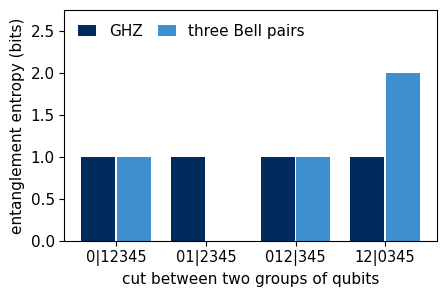

In [2]:
N = 6; D = 2 ** N
BITS = (np.arange(D)[:, None] >> (N - 1 - np.arange(N))) & 1     # bits s_i of every basis state, qubit 0 is the most significant bit
SPINS = 1 - 2 * BITS                                             # spins sigma_i = 1 - 2 s_i, bit 0 <-> spin +1

psi_ghz = np.zeros(D, complex); psi_ghz[0] = psi_ghz[-1] = 1 / np.sqrt(2)          # equation (2)
bell = np.array([1, 0, 0, 1], complex) / np.sqrt(2)
psi_bell = np.kron(np.kron(bell, bell), bell)                                      # equation (3), qubit 0 is the leftmost factor
TARGETS = {"GHZ": psi_ghz, "Bell": psi_bell}
TITLE = {"GHZ": "six-qubit GHZ state", "Bell": "three Bell pairs"}

def schmidt_values(psi, group):
    # singular values of the amplitude matrix with rows labelled by the qubits in `group` and columns by all other qubits
    rest = [q for q in range(N) if q not in group]
    matrix = np.transpose(np.reshape(psi, (2,) * N), list(group) + rest).reshape(2 ** len(group), -1)
    return np.linalg.svd(matrix, compute_uv=False)

def entropy_bits(psi, group):
    # equation (4): entanglement entropy in bits between the qubits in `group` and the rest
    lam = schmidt_values(psi, group) ** 2
    lam = lam[lam > 1e-14]
    return float(abs(-np.sum(lam * np.log2(lam))))

# all 31 ways of cutting six qubits into two groups: qubit 0 always belongs to the first group
CUTS = [[0] + [q for q in range(1, N) if (c >> (q - 1)) & 1] for c in range(2 ** (N - 1) - 1)]
SHOWN = {"0|12345": [0], "01|2345": [0, 1], "012|345": [0, 1, 2], "12|0345": [1, 2]}
print(f"{'entropy across the cut (bits)':32s}" + "".join(f"{cut:>10s}" for cut in SHOWN) + "   cuts with zero entropy")
for name, psi in TARGETS.items():
    product_cuts = sum(entropy_bits(psi, cut) < 1e-10 for cut in CUTS)
    print(f"{TITLE[name]:32s}" + "".join(f"{entropy_bits(psi, cut):10.3f}" for cut in SHOWN.values()) + f"   {product_cuts} of {len(CUTS)}")

fig, ax = plt.subplots(figsize=(4.6, 3.1))
x = np.arange(len(SHOWN))
ax.bar(x - 0.2, [entropy_bits(psi_ghz, cut) for cut in SHOWN.values()], width=0.38, color="#002B5C", label="GHZ")
ax.bar(x + 0.2, [entropy_bits(psi_bell, cut) for cut in SHOWN.values()], width=0.38, color="#3E8FD0", label="three Bell pairs")
ax.set_xticks(x); ax.set_xticklabels(SHOWN, fontsize=10.5)
ax.set_xlabel("cut between two groups of qubits"); ax.set_ylabel("entanglement entropy (bits)")
ax.set_ylim(0, 2.75); ax.legend(frameon=False, loc="upper left", ncol=2, columnspacing=1.0, handlelength=1.2)
fig.tight_layout(); save(fig, "fig_lab081_targets"); plt.show()

The figure shows the entropy across four cuts, named by the qubits on each side. The GHZ state has one bit of entropy across every one of the 31 cuts, so no partition into two or more groups makes it a product, and its depth is six. The three Bell pairs have zero entropy across the cut 01|2345 and across the two other cuts that separate whole pairs, three cuts in total. A cut through one pair gives one bit and the cut 12|0345, which goes through two pairs, gives two bits.

The lecture tests a product across a cut with four amplitudes, $\psi(a,b)\,\psi(a',b')=\psi(a,b')\,\psi(a',b)$, where $a,a'$ are bit strings of the group $A$ and $b,b'$ bit strings of the rest $B$. We evaluate this test on the two targets with the amplitudes of the previous cell. For the GHZ state across $012|345$ we take $a=b=000$ and $a'=b'=111$, and over all 31 cuts we record the largest violation $|\psi(a,b)\psi(a',b')-\psi(a,b')\psi(a',b)|$. For the Bell pairs we compute the largest violation across $01|2345$, which separates the pair $(0,1)$ from the other two, and across $0|12345$, which cuts this pair. A vanishing violation goes with zero entropy, as the rank-one condition above requires.

In [ ]:
def amp(psi, bits):
    # amplitude of the bit string written as text, qubit 0 first (most significant bit)
    return psi[int(bits, 2)].real

def largest_violation(psi, group):
    # amplitude matrix of the cut (rows: strings of `group`, columns: strings of the rest), largest |M[a,b] M[a',b'] - M[a,b'] M[a',b]|
    rest = [q for q in range(N) if q not in group]
    M = np.transpose(np.reshape(psi, (2,) * N), list(group) + rest).reshape(2 ** len(group), -1)
    minors = np.einsum("ab,cd->acbd", M, M) - np.einsum("ad,cb->acbd", M, M)
    return float(np.max(np.abs(minors)))

left, right = amp(psi_ghz, "000000") * amp(psi_ghz, "111111"), amp(psi_ghz, "000111") * amp(psi_ghz, "111000")
print(f"GHZ, cut 012|345:   psi(000000) psi(111111) = {left:.3f},   psi(000111) psi(111000) = {right:.3f}")
print(f"GHZ, smallest of the largest violations over all {len(CUTS)} cuts: {min(largest_violation(psi_ghz, cut) for cut in CUTS):.3f}")
print(f"Bell pairs, largest violation across 01|2345: {largest_violation(psi_bell, [0, 1]):.3f}")
print(f"Bell pairs, largest violation across 0|12345:  {largest_violation(psi_bell, [0]):.3f}")


GHZ, cut 012|345:   psi(000000) psi(111111) = 0.500,   psi(000111) psi(111000) = 0.000
GHZ, smallest of the largest violations over all 31 cuts: 0.500
Bell pairs, largest violation across 01|2345: 0.000
Bell pairs, largest violation across 0|12345:  0.125


## 3. Random Pauli measurements

A measurement setting $\mathbf q=(q_0,\dots,q_5)$ with $q_i\in\{x,y,z\}$ tells along which axis each qubit is measured. The code writes the axes as `"X"`, `"Y"` and `"Z"`, and the code, the printed lines and the figure titles call a setting a basis pattern, or pattern. The device turns qubit $i$ by $\hat R_{q_i}$ and then reads all qubits along $z$, with
$$\hat R_z=\hat I,\qquad \hat R_x=\hat H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix},\qquad \hat R_y=\hat H\hat S^\dagger=\frac{1}{\sqrt2}\begin{pmatrix}1&-i\\1&i\end{pmatrix}$$
in the basis $|0\rangle,|1\rangle$, where $\hat H$ is the Hadamard gate and $\hat S^\dagger=\mathrm{diag}(1,-i)$. The outcome is a bit string $\mathbf s=s_0s_1\dots s_5$, where $s_i=0$ stands for the eigenvalue $+1$ of the measured Pauli operator. For a pure state $|\Psi\rangle$ its Born probability is
$$p(\mathbf s\,|\,\mathbf q)=\big|\langle\mathbf s|\,\hat R_{q_0}\otimes\dots\otimes\hat R_{q_5}\,|\Psi\rangle\big|^2 . \tag{5}$$
The record consists of $n_q=100$ settings $\mathbf q_\tau$, $\tau=1,\dots,n_q$, drawn uniformly from the $3^6=729$ possible ones, each measured $n_{\rm s}=400$ times, and we store the counts $n_\tau(\mathbf s)$ of every bit string. The code applies the six single-qubit rotations to the $2\times2\times\dots\times2$ tensor of amplitudes, which avoids $64\times64$ matrices.

The information that a setting carries about entanglement depends on its axes. To see this, we compare the GHZ state with a device that prepares $|000000\rangle$ or $|111111\rangle$ at random, each with the probability one half. This statistical mixture of two product states is written as the density matrix
$$\hat\rho_{\rm mix}=\tfrac12|000000\rangle\langle000000|+\tfrac12|111111\rangle\langle111111| , \tag{6}$$
which contains no entanglement and has depth one. Its probability of an outcome is the average of the probabilities of its two product states. The cell checks in which of the 729 settings the two give different probabilities, and it marks the settings of our record that belong to this set.

rotation check, largest deviation: 2.3810519563489838e-18
six-qubit GHZ state : 100 patterns (98 different), 40000 bit strings, first patterns ['YXXXZZ', 'XXZXZY', 'XYZXXY', 'ZZXZYY'], loss of the exact state 3.2717 nats
three Bell pairs    : 100 patterns (94 different), 40000 bit strings, first patterns ['YZYXXY', 'YZZXZY', 'XZZZZY', 'YXZYXY'], loss of the exact state 3.5073 nats
GHZ state and mixture (6) give different probabilities in 32 of 729 patterns; these are the patterns without Z and with an even number of Y: True
GHZ record, patterns without Z and with an even number of Y: ['YXYYXY', 'YYYYYY']


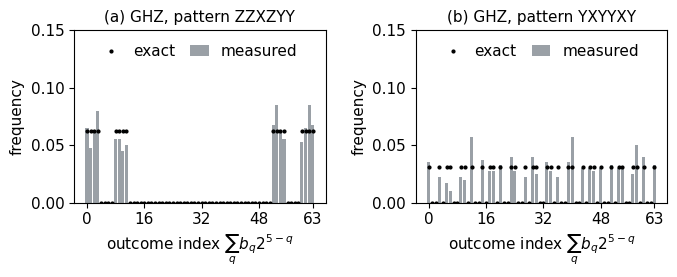

In [3]:
HADAMARD = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
S_DAGGER = np.diag([1, -1j])
ROTATION = {"X": HADAMARD, "Y": HADAMARD @ S_DAGGER, "Z": np.eye(2, dtype=complex)}     # R_X, R_Y, R_Z of equation (5)

def pattern_unitaries(patterns):
    # patterns: K strings such as "XZYYXZ" -> array (K, N, 2, 2) with the rotation of every qubit
    return np.array([[ROTATION[axis] for axis in pattern] for pattern in patterns])

def rotate(psi, U1):
    # applies the rotation of qubit q to axis q of the amplitude tensor, for all K patterns at once -> (K, 64)
    phi = jnp.broadcast_to(jnp.reshape(psi, (1,) + (2,) * N), (U1.shape[0],) + (2,) * N)
    letters = "abcdef"
    for q in range(N):
        phi = jnp.einsum(f"kz{letters[q]},k{letters}->k{letters.replace(letters[q], 'z')}", U1[:, q], phi)
    return phi.reshape(U1.shape[0], D)

def kron_all(mats):
    out = np.ones((1, 1), complex)
    for m in mats:
        out = np.kron(out, m)          # qubit 0 is the leftmost factor
    return out

def measure(probabilities, M, rng):
    # M shots for every pattern: counts n_k(s) drawn from the Born probabilities p(s | q_k)
    return np.array([rng.multinomial(M, p / p.sum()) for p in probabilities])

def cross_entropy(counts, probabilities):
    # equation (9) for given probabilities, in nats per shot
    return float(-np.sum(counts * np.log(np.where(counts > 0, probabilities, 1.0))) / counts.sum())

def record(psi, K, M, seed):
    rng = np.random.default_rng(seed)
    patterns = ["".join(rng.choice(list("XYZ"), size=N)) for _ in range(K)]
    U1 = pattern_unitaries(patterns)
    exact = np.abs(np.asarray(rotate(psi, U1))) ** 2                     # equation (5), known in a simulation only
    counts = measure(exact, M, rng)
    return dict(patterns=patterns, U1=jnp.asarray(U1), exact=exact, counts=counts, L_exact=cross_entropy(counts, exact))

K_PATTERNS, M_SHOTS = 100, 400
DATA = {"GHZ": record(psi_ghz, K_PATTERNS, M_SHOTS, seed=8101), "Bell": record(psi_bell, K_PATTERNS, M_SHOTS, seed=8102)}

# check of the qubit-by-qubit rotation against the 64 x 64 Kronecker product for one pattern
pattern0 = DATA["GHZ"]["patterns"][0]
direct = kron_all([ROTATION[axis] for axis in pattern0]) @ psi_bell
print("rotation check, largest deviation:", float(np.max(np.abs(np.asarray(rotate(psi_bell, pattern_unitaries([pattern0])))[0] - direct))))

def coherence_patterns(patterns):
    # patterns without Z and with an even number of Y: the only ones in which the GHZ state differs from the mixture (6)
    return [p for p in patterns if "Z" not in p and p.count("Y") % 2 == 0]

for name, d in DATA.items():
    print(f"{TITLE[name]:20s}: {len(d['patterns'])} patterns ({len(set(d['patterns']))} different), {d['counts'].sum()} bit strings,"
          f" first patterns {d['patterns'][:4]}, loss of the exact state {d['L_exact']:.4f} nats")
# in which of the 729 patterns does the GHZ state differ from the mixture (6) of |000000> and |111111>
import itertools
ALL_PATTERNS = ["".join(p) for p in itertools.product("XYZ", repeat=N)]
U_all = pattern_unitaries(ALL_PATTERNS)
e0 = np.zeros(D, complex); e0[0] = 1; e1 = np.zeros(D, complex); e1[-1] = 1
p_ghz = np.abs(np.asarray(rotate(psi_ghz, U_all))) ** 2
p_mix = 0.5 * np.abs(np.asarray(rotate(e0, U_all))) ** 2 + 0.5 * np.abs(np.asarray(rotate(e1, U_all))) ** 2
differ = [p for p, d_ in zip(ALL_PATTERNS, np.max(np.abs(p_ghz - p_mix), axis=1)) if d_ > 1e-12]
print(f"GHZ state and mixture (6) give different probabilities in {len(differ)} of {len(ALL_PATTERNS)} patterns;"
      f" these are the patterns without Z and with an even number of Y: {sorted(differ) == sorted(coherence_patterns(ALL_PATTERNS))}")
NUMBERS.update(CoherencePatternsOfAll=f"{len(differ)}")
ghz_coherence = coherence_patterns(DATA["GHZ"]["patterns"])
print("GHZ record, patterns without Z and with an even number of Y:", ghz_coherence)
NUMBERS.update(Patterns=f"{K_PATTERNS}", ShotsPerPattern=f"{M_SHOTS}", ShotsTotal=f"{K_PATTERNS * M_SHOTS}",
               GhzCoherencePatterns=f"{len(ghz_coherence)}", LossExactGHZ=f"{DATA['GHZ']['L_exact']:.3f}",
               LossExactBell=f"{DATA['Bell']['L_exact']:.3f}")

d = DATA["GHZ"]
k_z = next(k for k, p in enumerate(d["patterns"]) if p.count("Z") == 3)
k_xy = d["patterns"].index(ghz_coherence[0])
def draw_pattern(k):
    def draw(ax, lab):
        ax.bar(np.arange(D), d["counts"][k] / M_SHOTS, width=0.85, color=COL["data"], label="measured")
        ax.plot(np.arange(D), d["exact"][k], ".", color=COL["exact"], ms=4, label="exact")
        ax.set_xlabel(r"outcome index $\sum_q b_q 2^{5-q}$"); ax.set_ylabel("frequency")
        ax.set_xticks([0, 16, 32, 48, 63]); ax.set_ylim(0, 0.15)
        ax.set_title((lab + " " if lab else "") + "GHZ, pattern " + d["patterns"][k], fontsize=11)
        ax.legend(loc="upper center", ncol=2, frameon=False, handlelength=1.2, columnspacing=1.0)
    return draw
panels("fig_lab081_record", [draw_pattern(k_z), draw_pattern(k_xy)])

The GHZ state and the mixture (6) differ in 32 of the 729 settings, those without any $z$ and with an even number of $y$. A random setting is of this kind with probability $32/729\approx0.044$, and the GHZ record contains two of them among its 100 settings. Panel (a) shows a setting with three $z$ axes. The three qubits measured along $z$ return 000 or 111 and the other three are uniformly random, which gives 16 outcomes of probability $1/16$, and the mixture (6) would give the same picture. Panel (b) shows one of the two settings without $z$ and with an even number of $y$. Half of the 64 outcomes never occur, which is the interference between the two components of the GHZ state. Grey bars are measured frequencies from 400 shots and black dots the exact probabilities (5). The horizontal axis is the index of the bit string as a binary number, and its label writes $b_q$ for the bit $s_i$ of qubit $i$, with $q$ there a qubit index of the code and no setting.

## 4. The RBM wave function and its likelihood

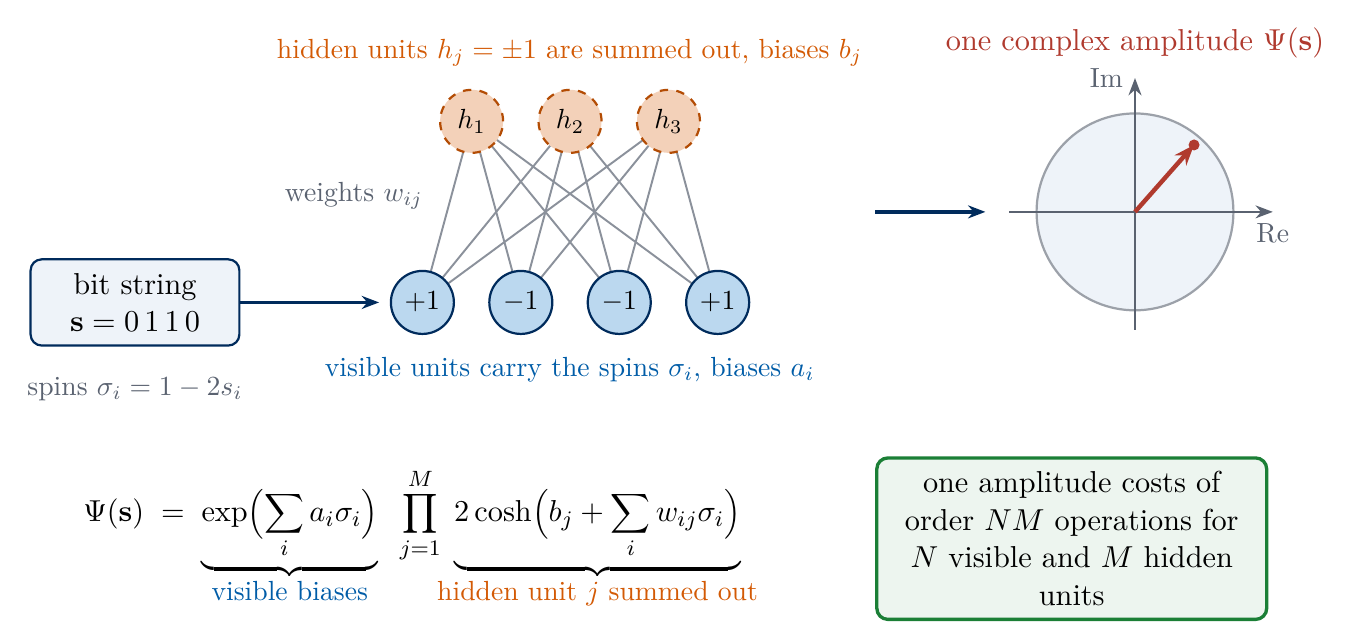

The sketch shows the network of Lab 080 with complex parameters, so that one amplitude is a complex number.

We write a bit string $\mathbf s$ through the spins $\sigma_i=1-2s_i=\pm1$, as in the lecture. An RBM with $N$ visible spins and $M$ hidden units has visible biases $a_i$, hidden biases $b_j$ and weights $w_{ij}$, here all complex. Summing over the hidden units gives the amplitude built in Lab 080 [3], where all parameters are real,
$$\tilde\Psi_\theta(\mathbf s)=\exp\Big(\sum_i a_i\sigma_i\Big)\prod_{j=1}^{M}2\cosh\Big(b_j+\sum_iw_{ij}\sigma_i\Big) , \tag{7}$$
where $\theta$ collects all parameters. The code keeps the names of the recorded run, `BITS` and `SPINS` for the bits $s_i$ and the spins $\sigma_i$ of every basis state, and `a`, `c` and `W` for the real and imaginary parts of $a_i$, $b_j$ and $w_{ij}$. With six qubits we normalise it by the exact sum over the 64 bit strings,
$$|\Psi_\theta\rangle=\frac{1}{\sqrt{\sum_{\mathbf s}|\tilde\Psi_\theta(\mathbf s)|^2}}\sum_{\mathbf s}\tilde\Psi_\theta(\mathbf s)\,|\mathbf s\rangle . \tag{8}$$
Inserting $|\Psi_\theta\rangle$ into equation (5) gives the model probability $p_\theta(\mathbf s\,|\,\mathbf q)$ of every outcome in every setting. Measurements along $x$ and $y$ need no change of the network, because the rotations act on the vector of amplitudes. The network is fitted to the record by minimising the negative log-likelihood per shot, in nats [1,4],
$$\mathcal L(\theta)=-\frac{1}{n_q\,n_{\rm s}}\sum_{\tau=1}^{n_q}\sum_{\mathbf s}n_\tau(\mathbf s)\,\ln p_\theta(\mathbf s\,|\,\mathbf q_\tau) . \tag{9}$$
A lower $\mathcal L$ means that the model gives the observed bit strings a higher probability. The loss cannot reach zero, since even the exact state predicts each outcome only with its Born probability. We call the value of expression (9) with the exact probabilities the loss of the exact state. It is available in a simulation only, and the cell of Section 3 printed it for both records, $3.272$ and $3.507$ nats. A flexible network can end slightly below this value by fitting the statistical fluctuations of the finite record.

We take $M=12$, two hidden units per qubit. The cell defines the amplitudes and the loss, and evaluates them for random parameters.

In [4]:
N_HIDDEN = 12                                   # two hidden units for every qubit

def init_params(key, scale=0.1):
    # real and imaginary parts of a (N), c = hidden biases b_j (N_HIDDEN) and W = weights w_ij (N x N_HIDDEN), independent normal numbers of width `scale`
    k = jax.random.split(key, 3)
    return dict(a=scale * jax.random.normal(k[0], (2, N)), c=scale * jax.random.normal(k[1], (2, N_HIDDEN)),
                W=scale * jax.random.normal(k[2], (2, N, N_HIDDEN)))

def amplitudes(params, mask):
    # equations (7) and (8): all 64 amplitudes of the RBM, normalised; mask (N x N_HIDDEN) multiplies the weights
    a = params["a"][0] + 1j * params["a"][1]
    c = params["c"][0] + 1j * params["c"][1]
    W = (params["W"][0] + 1j * params["W"][1]) * mask
    log_psi = SPINS @ a + jnp.sum(jnp.log(2 * jnp.cosh(c + SPINS @ W)), axis=1)
    psi = jnp.exp(log_psi - jnp.max(jnp.real(log_psi)))                  # the largest amplitude has modulus one
    return psi / jnp.sqrt(jnp.sum(jnp.abs(psi) ** 2))

def nll(params, mask, U1, counts):
    # equation (9): negative log-likelihood per shot of the counts n_k(s) under the Born probabilities of the network
    p = jnp.abs(rotate(amplitudes(params, mask), U1)) ** 2
    return -jnp.sum(counts * jnp.log(p + 1e-12)) / jnp.sum(counts)

FULL_MASK = jnp.ones((N, N_HIDDEN))
params_demo = init_params(jax.random.PRNGKey(0), scale=0.5)
psi_demo = amplitudes(params_demo, FULL_MASK)
n_real = sum(int(np.prod(v.shape)) for v in params_demo.values())
print(f"real parameters: {n_real} | norm of the untrained state: {float(jnp.sum(jnp.abs(psi_demo) ** 2)):.12f}")
p_demo = jnp.abs(rotate(psi_demo, DATA["GHZ"]["U1"])) ** 2
print(f"Born probabilities sum to one in every pattern: largest deviation {float(jnp.max(jnp.abs(p_demo.sum(1) - 1))):.1e}")
loss_untrained = float(nll(params_demo, FULL_MASK, DATA["GHZ"]["U1"], DATA["GHZ"]["counts"]))
print(f"loss of this untrained network on the GHZ record: {loss_untrained:.3f} nats"
      f" (uniform probabilities give ln 64 = {np.log(64):.3f}, the exact state gives {DATA['GHZ']['L_exact']:.3f})")
NUMBERS.update(Hidden=f"{N_HIDDEN}", Parameters=f"{n_real}", LossUntrained=f"{loss_untrained:.2f}")

real parameters: 180 | norm of the untrained state: 1.000000000000
Born probabilities sum to one in every pattern: largest deviation 1.4e-15
loss of this untrained network on the GHZ record: 8.139 nats (uniform probabilities give ln 64 = 4.159, the exact state gives 3.272)


The network has 180 real parameters, the real and imaginary parts of 6 visible biases, 12 hidden biases and 72 weights. With random parameters its loss on the GHZ record is $8.14$ nats, far above the $\ln64\approx4.16$ of uniform probabilities and the $3.27$ of the exact state.

## 5. Masks and factorisation

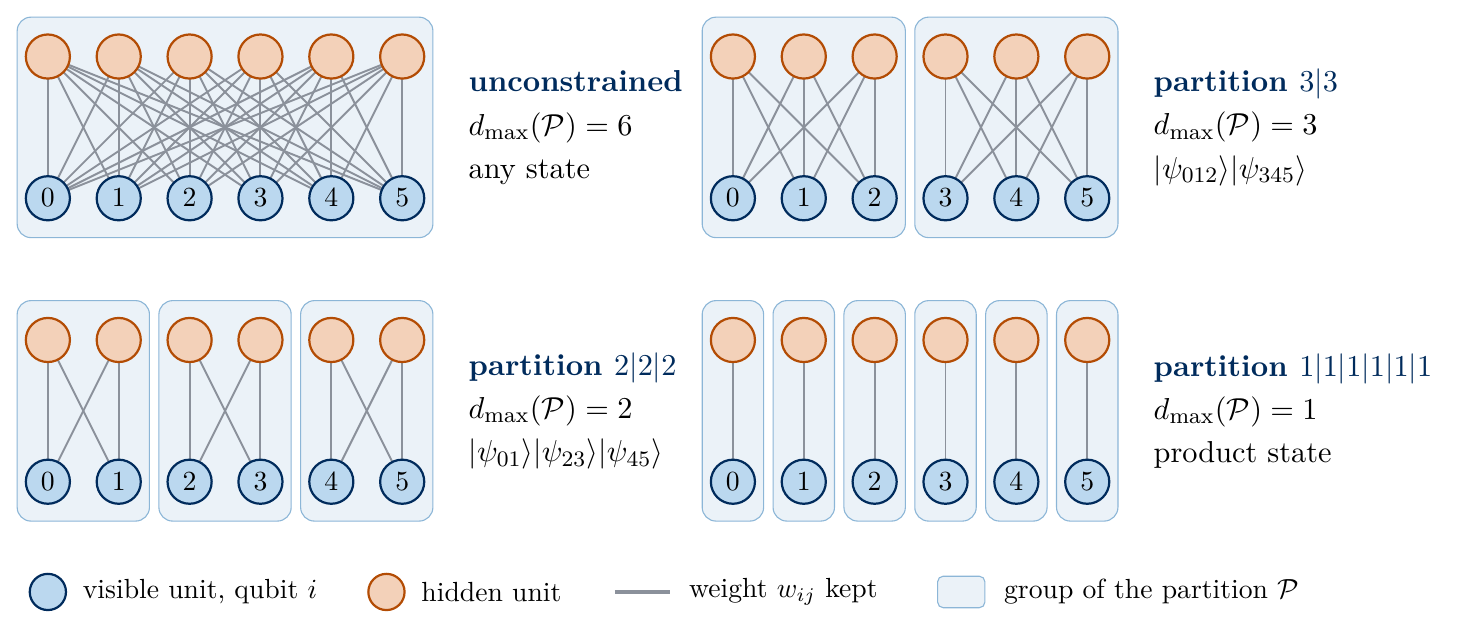

We attach hidden unit $j$, with $j=1,\dots,M$, to qubit $o(j)=\lfloor (j-1)/2\rfloor$, so that every qubit owns two hidden units. The code and the figure of the masks count the hidden units from 0 to 11. For a partition $\mathcal P$ the mask keeps a weight only if the qubit and the owner of the hidden unit lie in the same group,
$$w_{ij}\;\to\;m_{ij}w_{ij},\qquad m_{ij}=\begin{cases}1 & i \text{ and } o(j) \text{ in the same group of } \mathcal P,\\ 0 & \text{otherwise.}\end{cases} \tag{10}$$
Every factor of the product (7) then depends on the spins of one group only, and so does every factor $e^{a_i\sigma_i}$. Collecting the factors of each group gives
$$\tilde\Psi_\theta(\mathbf s)=\prod_{\gamma=1}^{n_G}\tilde\psi_\gamma(\mathbf s_{G_\gamma}) , \tag{11}$$
which is the product state (1). A network with the mask of $\mathcal P$ therefore represents only states whose depth is at most the size of the largest group,
$$d_{\max}(\mathcal P)=\max_\gamma|G_\gamma| .$$
A masked network of the code, the figure titles and Ref. [1] is the cut network of the lecture, and its mask $m_{ij}$ records which weights are kept. The cut networks are special cases of the unconstrained one, obtained by setting some of its weights to zero. Ref. [1] gives every group a hidden layer of its own, which leads to the same product form.

We use the five partitions of Ref. [1], named by the sizes of their groups of consecutive qubits. The partition 1|5 is $\{0\},\{1,\dots,5\}$, 2|4 is $\{0,1\},\{2,3,4,5\}$, 3|3 is $\{0,1,2\},\{3,4,5\}$, 2|2|2 is $\{0,1\},\{2,3\},\{4,5\}$ and 1|1|1|1|1|1 puts every qubit in its own group. We add a shifted partition into pairs, $\{1,2\},\{3,4\},\{5,0\}$, which has $d_{\max}=2$ like 2|2|2 and cuts through all three Bell pairs. The set covers $d_{\max}=1,2,3,4,5$. The cell draws the masks and checks the factorisation (11) with the random parameters of Section 4. For every cut network it prints the largest entropy (4) across the cuts between its own groups, the largest entropy over all 31 cuts, and for the mask 2|4 the difference between the 64 amplitudes and the product of the two group factors computed separately.

weights kept: {'unconstrained': 72, '1|5': 52, '2|4': 40, '3|3': 36, '2|2|2': 24, '2|2|2 shifted': 24, '1|1|1|1|1|1': 12}

       network  largest entropy across its own cuts   largest entropy over all 31 cuts   (bits)
 unconstrained                                  nan                              1.161
           1|5                              9.6e-16                              0.788
           2|4                              0.0e+00                              0.757
           3|3                              3.2e-16                              0.995
         2|2|2                              1.3e-15                              0.324
 2|2|2 shifted                              1.6e-15                              0.637
   1|1|1|1|1|1                              1.3e-15                              0.000

mask 2|4: largest difference between the product of the two group factors and the 64 masked amplitudes: 6.2e-16


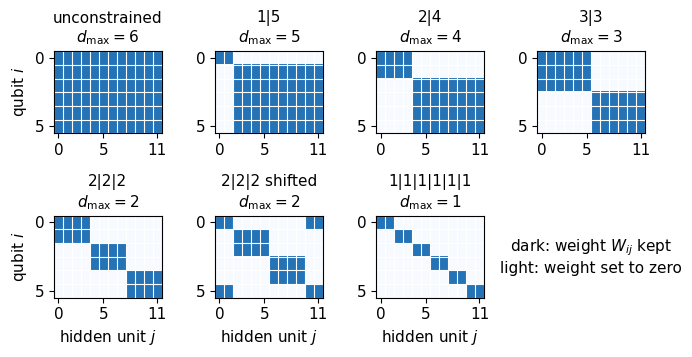

In [5]:
PARTITIONS = {"full": [[0, 1, 2, 3, 4, 5]], "1|5": [[0], [1, 2, 3, 4, 5]], "2|4": [[0, 1], [2, 3, 4, 5]],
              "3|3": [[0, 1, 2], [3, 4, 5]], "2|2|2": [[0, 1], [2, 3], [4, 5]], "2|2|2 shifted": [[1, 2], [3, 4], [5, 0]],
              "1|1|1|1|1|1": [[q] for q in range(N)]}
ARCH = list(PARTITIONS)
D_MAX = {name: max(len(group) for group in groups) for name, groups in PARTITIONS.items()}
LABEL = {name: ("unconstrained" if name == "full" else name) for name in ARCH}
SHORT = {**LABEL, "2|2|2 shifted": "2|2|2 sh.", "1|1|1|1|1|1": "1|1|...|1"}
OWNER = np.arange(N_HIDDEN) // (N_HIDDEN // N)          # hidden unit j is attached to qubit o(j) = floor(j / 2)

def mask_of(groups):
    # equation (10): the weight w_ij survives if qubit i and the qubit o(j) of hidden unit j lie in the same group
    group_of = np.zeros(N, int)
    for g, group in enumerate(groups):
        group_of[group] = g
    return (group_of[:, None] == group_of[OWNER][None, :]).astype(float)

MASKS = jnp.array([mask_of(PARTITIONS[name]) for name in ARCH])

fig, axes = plt.subplots(2, 4, figsize=(7.0, 3.7))
for ax, name in zip(axes.ravel(), ARCH):
    ax.imshow(mask_of(PARTITIONS[name]), cmap="Blues", vmin=0, vmax=1.35, aspect="auto")
    ax.set_xticks(np.arange(-0.5, N_HIDDEN), minor=True); ax.set_yticks(np.arange(-0.5, N), minor=True)
    ax.grid(which="minor", color="white", lw=0.8); ax.tick_params(which="minor", length=0)
    ax.set_xticks([0, 5, 11]); ax.set_yticks([0, 5])
    ax.set_title(f"{LABEL[name]}\n$d_{{\\max}}={D_MAX[name]}$", fontsize=11)
for ax in axes[:, 0]:
    ax.set_ylabel("qubit $i$")
for ax in axes[1, :3]:
    ax.set_xlabel("hidden unit $j$")
axes[1, 3].axis("off")
axes[1, 3].text(0.5, 0.5, "dark: weight $W_{ij}$ kept\nlight: weight set to zero", ha="center", va="center", fontsize=11,
                transform=axes[1, 3].transAxes)
fig.tight_layout(); save(fig, "fig_lab081_masks"); plt.show()
print("weights kept:", {LABEL[name]: int(np.sum(mask_of(PARTITIONS[name]))) for name in ARCH})

# factorisation (11), checked with the random parameters of Section 4 for every mask
print(f"\n{'network':>14s} {'largest entropy across its own cuts':>36s} {'largest entropy over all 31 cuts':>34s}   (bits)")
own_cut_entropy = 0.0
for i, name in enumerate(ARCH):
    psi = np.asarray(amplitudes(params_demo, MASKS[i]))
    own = max([entropy_bits(psi, group) for group in PARTITIONS[name] if len(group) < N], default=float("nan"))
    overall = max(entropy_bits(psi, cut) for cut in CUTS)
    own_cut_entropy = max(own_cut_entropy, 0.0 if np.isnan(own) else own)
    print(f"{LABEL[name]:>14s} {own:36.1e} {overall:34.3f}")

def group_amplitudes(params, mask, group):
    # the factor psi_g of equation (11): the biases of the qubits in the group and the hidden units attached to them
    a = np.asarray(params["a"][0] + 1j * params["a"][1])
    c = np.asarray(params["c"][0] + 1j * params["c"][1])
    W = np.asarray(params["W"][0] + 1j * params["W"][1]) * np.asarray(mask)
    hidden = [j for j in range(N_HIDDEN) if OWNER[j] in group]
    s = SPINS[:, group]
    return np.exp(s @ a[group]) * np.prod(2 * np.cosh(c[hidden] + s @ W[np.ix_(group, hidden)]), axis=1)

i_24 = ARCH.index("2|4")
product = np.prod([group_amplitudes(params_demo, MASKS[i_24], g) for g in PARTITIONS["2|4"]], axis=0)
product /= np.linalg.norm(product)
factorisation_error = float(np.max(np.abs(product - np.asarray(amplitudes(params_demo, MASKS[i_24])))))
print(f"\nmask 2|4: largest difference between the product of the two group factors and the 64 masked amplitudes: {factorisation_error:.1e}")
NUMBERS.update(FactorisationError=f"{factorisation_error:.0e}", OwnCutEntropy=f"{own_cut_entropy:.0e}")

Each panel shows one mask as a matrix with the six qubits as rows and the twelve hidden units as columns. The unconstrained network keeps all 72 weights, and the cut networks keep 52, 40, 36, 24, 24 and 12. With random parameters the entropy of the state of every cut network vanishes to numerical precision across the cuts between its own groups. Entanglement inside the groups remains, as the last column of the output shows, except in the fully factorised network, which is a product state. For the mask 2|4 the product of the two group factors agrees with the 64 amplitudes to numerical precision.

## 6. Training on the same record

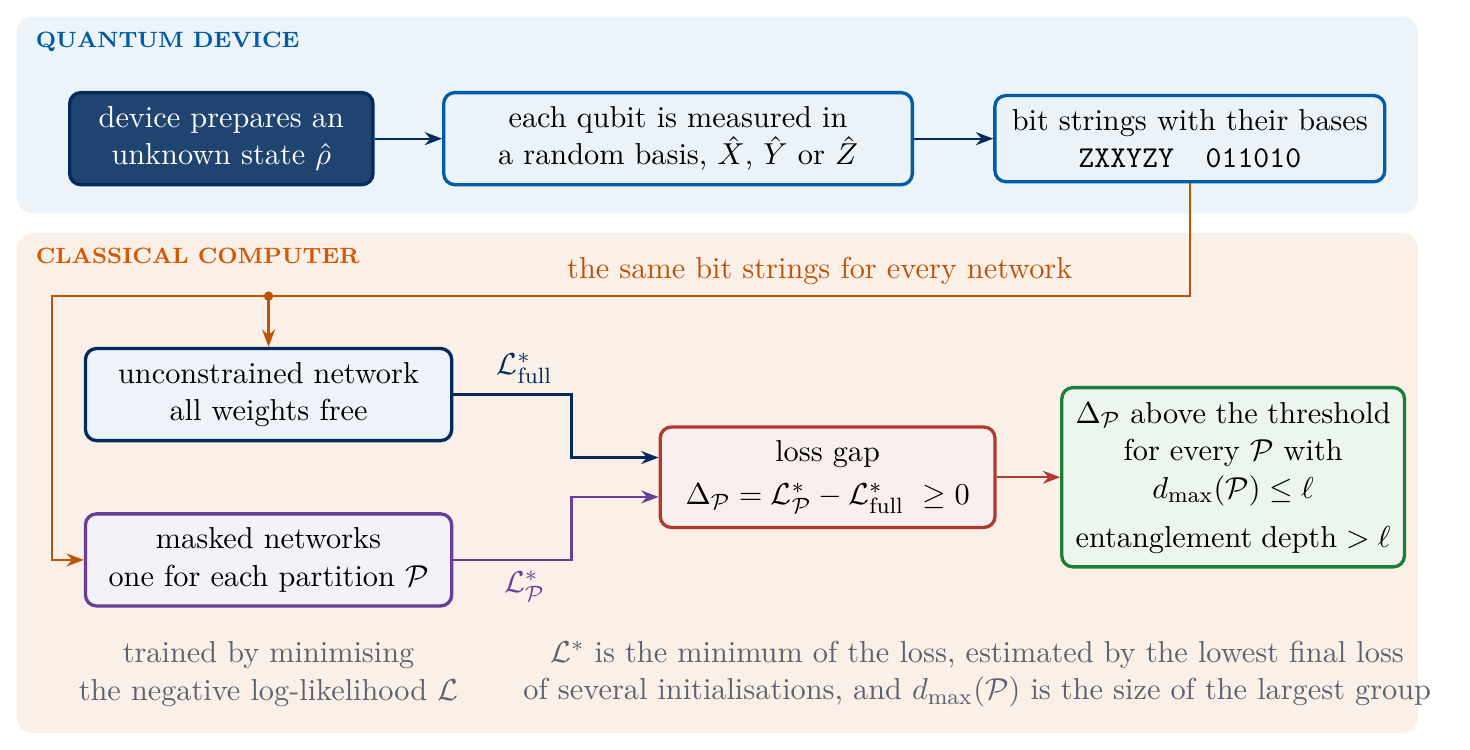

All seven networks are trained on the same record of a state by minimising the loss (9) with Adam [5], a variant of gradient descent with a step size adapted to every parameter, written out in a few lines of the cell. The gradient comes from `jax.grad` [6]. The step size starts at $0.02$ and decreases to zero along a cosine over 600 steps. The result of a minimisation depends on where it starts, so every network is trained from four random initialisations. The cell trains $7\times4$ networks for each of the two records and plots the loss during training.

six-qubit GHZ state : 7 networks x 4 initialisations x 600 Adam steps in 15.2 s
three Bell pairs    : 7 networks x 4 initialisations x 600 Adam steps in 6.7 s


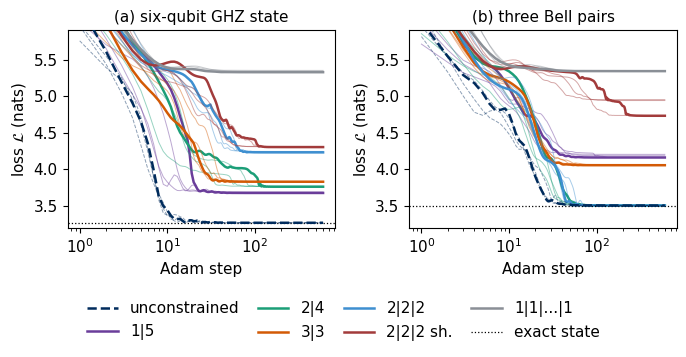

In [6]:
STEPS, LEARNING_RATE, N_INIT = 600, 0.02, 4

def make_trainer(loss, steps, lr):
    value_and_grad = jax.value_and_grad(loss)
    def train(params, mask, U1, counts):
        def step(carry, t):
            # one Adam step [5]: carry = (parameters, running mean of the gradient, running mean of its square)
            p, m, v = carry
            L, grad = value_and_grad(p, mask, U1, counts)
            m = jax.tree_util.tree_map(lambda m_, g_: 0.9 * m_ + 0.1 * g_, m, grad)
            v = jax.tree_util.tree_map(lambda v_, g_: 0.999 * v_ + 0.001 * g_ ** 2, v, grad)
            eta = lr * 0.5 * (1 + jnp.cos(jnp.pi * t / steps))               # step size on a cosine from lr to zero
            p = jax.tree_util.tree_map(lambda p_, m_, v_: p_ - eta * (m_ / (1 - 0.9 ** (t + 1)))
                                       / (jnp.sqrt(v_ / (1 - 0.999 ** (t + 1))) + 1e-8), p, m, v)
            return (p, m, v), L
        zeros = jax.tree_util.tree_map(jnp.zeros_like, params)
        (params, _, _), history = jax.lax.scan(step, (params, zeros, zeros), jnp.arange(steps))
        return params, history, loss(params, mask, U1, counts)                # trained parameters, loss curve, final loss
    # inner vmap: several initialisations of one network; outer vmap: all networks (one mask each)
    return jax.jit(jax.vmap(jax.vmap(train, in_axes=(0, None, None, None)), in_axes=(0, 0, None, None)))

def initial(init, seed, n_init):
    keys = jax.random.split(jax.random.PRNGKey(seed), len(ARCH) * n_init).reshape(len(ARCH), n_init, 2)
    return jax.vmap(jax.vmap(init))(keys)

def select(params, i, r):
    return jax.tree_util.tree_map(lambda x: x[i, r], params)

train_pure = make_trainer(nll, STEPS, LEARNING_RATE)
FIT = {}
for seed, (name, d) in zip((8111, 8112), DATA.items()):
    t0 = time.perf_counter()
    params, history, final = train_pure(initial(init_params, seed, N_INIT), MASKS, d["U1"], jnp.asarray(d["counts"], dtype=float))
    FIT[name] = dict(params=params, history=np.asarray(history), final=np.asarray(final), seconds=time.perf_counter() - t0)
    print(f"{TITLE[name]:20s}: {len(ARCH)} networks x {N_INIT} initialisations x {STEPS} Adam steps in {FIT[name]['seconds']:.1f} s")
NUMBERS.update(Steps=f"{STEPS}", Inits=f"{N_INIT}")

def draw_training(name):
    def draw(ax, lab):
        fit = FIT[name]
        for i, arch in enumerate(ARCH):
            best = int(np.argmin(fit["final"][i]))
            for r in range(N_INIT):
                ax.plot(np.arange(1, STEPS + 1), fit["history"][i, r], color=COL[arch], lw=1.8 if r == best else 0.7,
                        alpha=1.0 if r == best else 0.45, label=SHORT[arch] if r == best else None,
                        ls="--" if arch == "full" else "-", zorder=3 if arch == "full" else 2)
        ax.axhline(DATA[name]["L_exact"], color=COL["exact"], lw=0.9, ls=":", label="exact state")
        ax.set_xscale("log"); ax.set_xlabel("Adam step"); ax.set_ylabel(r"loss $\mathcal{L}$ (nats)")
        ax.set_ylim(3.2, 5.9)
        ax.set_title((lab + " " if lab else "") + TITLE[name], fontsize=11)
    return draw
panels("fig_lab081_training", [draw_training("GHZ"), draw_training("Bell")], figsize=(7.0, 3.0), legend=True)

Panel (a) shows the GHZ record and panel (b) the record of the three Bell pairs, with the loss against the Adam step on a logarithmic axis. Each colour is one network, the thick line is its best initialisation and the thin lines are the other three. The dotted line is the loss of the exact state. For both records the unconstrained network (dashed) reaches this line. For the GHZ record every cut network stops at a higher loss, on a plateau of its own. For the Bell pairs the networks 2|4 and 2|2|2 reach the same loss as the unconstrained one, and the other four stay above it. Some thin lines end above the thick line of the same colour, so a single training run can stop in a local minimum.

## 7. Loss gaps, threshold and the bound on the depth

For every network we take the lowest final loss over the four initialisations and call it $\mathcal L^*_{\mathcal P}$, or $\mathcal L^*_{\rm full}$ for the unconstrained network. The loss gap of a partition is [1]
$$\Delta_{\mathcal P}=\mathcal L^*_{\mathcal P}-\mathcal L^*_{\rm full} . \tag{12}$$
Every cut network is a special case of the unconstrained one, so $\Delta_{\mathcal P}\ge0$ holds when both losses are at their global minima. If the state behind the record is a product over the groups of $\mathcal P$, the cut network can fit the record as well as the unconstrained one and the gap is close to zero. A large gap means that the cut network found no state that explains the record. Training is not guaranteed to reach the global minimum. A run that stops in a local minimum ends above the optimum of its network and never below it, so the lowest of the four final losses is the best estimate of $\mathcal L^*_{\mathcal P}$ that we have. If all runs of a cut network stop in local minima, its gap is too large and its partition can be excluded wrongly, whereas an unconstrained network that stops early makes all gaps too small or even negative. Several initialisations per network reduce both risks.

A gap therefore counts only if it exceeds what the optimisation and the finite record leave undetermined. Ref. [1] determines the threshold $\Delta_{\rm th}$ “heuristically based on the typical stability of the loss function after convergence” and treats differences comparable to the residual fluctuations of the optimisation, typically below $10^{-3}$ nats there, as insignificant. Ref. [1] gives no formula for these fluctuations, so we state a rule of our own with two contributions.

The first contribution is the uncertainty of the optimisation. Every gap is measured from $\mathcal L^*_{\rm full}$, and the four runs of the unconstrained network show how well the optimisation determines this reference. We use the spread $s_{\rm full}$ of their final losses, the largest minus the smallest of the four values. The spreads of the cut networks do not enter the threshold. A large spread of a cut network signals local minima of that network, which can inflate its own gap and are countered by its several initialisations.

The second contribution is shot noise. A record of $N_{\rm s}=n_q\,n_{\rm s}$ shots is a finite sample, and a model with free parameters adapts to its random fluctuations. For maximum likelihood with $n$ free parameters the best fit exceeds the true distribution in total log-likelihood by about $n/2$ on average [7], so its loss per shot lies lower by about $n/(2N_{\rm s})$. A cut network that contains the true state has fewer parameters and gains less, so the unconstrained network can open a gap of at most about this size from noise alone. We count the parameters of the states that the unconstrained network can represent. The network has 180 real parameters, whereas a normalised pure state of six qubits without its global phase has $n_{\rm eff}=2\cdot2^6-2=126$. The threshold is
$$\Delta_{\rm th}=s_{\rm full}+\frac{n_{\rm eff}}{2N_{\rm s}} ,$$
and with $N_{\rm s}=40\,000$ the second term equals $0.0016$ nats per shot. The criterion of Ref. [1] then reads
$$\Delta_{\mathcal P}>\Delta_{\rm th}\ \text{ for every tested partition } \mathcal P \text{ with } d_{\max}(\mathcal P)\le\ell\quad\Longrightarrow\quad d_e>\ell . \tag{13}$$
A single partition with $d_{\max}(\mathcal P)\le\ell$ whose gap stays below the threshold would let a product over groups of at most $\ell$ qubits explain the record, so the bound requires all of them to fail. It holds within the tested partitions and, with one network per partition, within pure states.

The cell prints, for every network, $\mathcal L^*$, the gap, the spread, the gap in units of the threshold, and the gap multiplied by the 40 000 shots, which is the difference of the total log-likelihoods. It also prints the fidelity $|\langle\Psi_{\rm target}|\Psi_\theta\rangle|^2$ of the best run with the exact state. The fidelity is a diagnostic that only a simulation offers and it plays no part in the criterion.


six-qubit GHZ state: loss of the exact state 3.27165, best unconstrained loss 3.27159, difference 0.00006; threshold 0.00161 = spread 0.00004 + shot noise 0.00158
       network d_max       L*       gap   spread  gap/threshold  gap x shots  fidelity  verdict
 unconstrained     6   3.2716   0.00000  0.00004            0.0            0     1.000  reference
           1|5     5   3.6789   0.40736  0.01433          252.3        16294     0.441  disfavoured
           2|4     4   3.7640   0.49237  0.00687          305.0        19695     0.490  disfavoured
           3|3     3   3.8320   0.56042  0.00434          347.1        22417     0.240  disfavoured
         2|2|2     2   4.2332   0.96156  0.01293          595.6        38462     0.217  disfavoured
 2|2|2 shifted     2   4.3053   1.03375  0.00788          640.3        41350     0.222  disfavoured
   1|1|1|1|1|1     1   5.3282   2.05662  0.02456         1273.8        82265     0.029  disfavoured

three Bell pairs: loss of the exact state

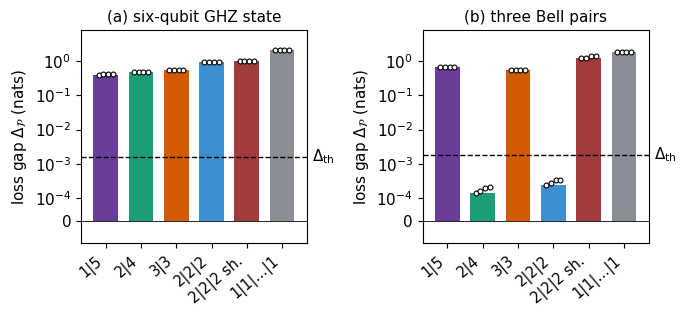

In [7]:
SHOTS_TOTAL = K_PATTERNS * M_SHOTS
N_EFF_PURE = min(n_real, 2 * D - 2)      # a normalised pure state of 64 amplitudes without its global phase has 2D - 2 real parameters

def analyse(final, n_eff):
    # final: losses (network, initialisation). L*_P is the smallest one over the initialisations, the gap is equation (12).
    # The threshold of Section 7 adds two terms: the spread of the final loss of the unconstrained network (row 0) over its
    # initialisations, and the loss n_eff / (2 * shots) that a model with n_eff free parameters gains by fitting shot noise.
    # The spreads of the masked networks are printed as a diagnostic of their local minima and do not enter the threshold.
    best = final.min(axis=1)
    spread = final.max(axis=1) - best
    shot_term = n_eff / (2 * SHOTS_TOTAL)
    return dict(best=best, gap=best - best[0], gap_runs=final - best[0], spread=spread, threshold=float(spread[0] + shot_term),
                optimisation_term=float(spread[0]), shot_term=shot_term, n_eff=n_eff,
                largest_masked_spread=float(spread[1:].max()), best_run=final.argmin(axis=1))

def depth_bound(gap, threshold):
    # criterion (13): the largest l such that every tested masked network with d_max <= l has a gap above the threshold
    l = 0
    while l + 1 < N and all(gap[i] > threshold for i, arch in enumerate(ARCH) if arch != "full" and D_MAX[arch] <= l + 1):
        l += 1
    return l

def verdict(arch, gap, threshold):
    return "reference" if arch == "full" else ("disfavoured" if gap > threshold else "compatible")

GAPS = {}
for name, fit in FIT.items():
    g = analyse(fit["final"], N_EFF_PURE)
    # diagnostic that needs the exact state: fidelity of the best run of every network with the target
    g["fidelity"] = np.array([abs(np.vdot(TARGETS[name], np.asarray(amplitudes(select(fit["params"], i, int(g["best_run"][i])), MASKS[i])))) ** 2
                              for i in range(len(ARCH))])
    g["overfit"] = DATA[name]["L_exact"] - g["best"][0]
    g["bound"] = depth_bound(g["gap"], g["threshold"])
    GAPS[name] = g
    print(f"\n{TITLE[name]}: loss of the exact state {DATA[name]['L_exact']:.5f}, best unconstrained loss {g['best'][0]:.5f},"
          f" difference {g['overfit']:.5f}; threshold {g['threshold']:.5f} = spread {g['optimisation_term']:.5f} + shot noise {g['shot_term']:.5f}")
    print(f"{'network':>14s} {'d_max':>5s} {'L*':>8s} {'gap':>9s} {'spread':>8s} {'gap/threshold':>14s} {'gap x shots':>12s} {'fidelity':>9s}  verdict")
    for i, arch in enumerate(ARCH):
        print(f"{LABEL[arch]:>14s} {D_MAX[arch]:5d} {g['best'][i]:8.4f} {g['gap'][i]:9.5f} {g['spread'][i]:8.5f} "
              f"{g['gap'][i] / g['threshold']:14.1f} {g['gap'][i] * K_PATTERNS * M_SHOTS:12.0f} {g['fidelity'][i]:9.3f}  {verdict(arch, g['gap'][i], g['threshold'])}")
print()
for name, g in GAPS.items():
    compatible = [LABEL[a] for i, a in enumerate(ARCH) if a != "full" and g["gap"][i] <= g["threshold"]]
    print(f"{TITLE[name]:20s}: every tested masked network with d_max <= {g['bound']} has a gap above the threshold"
          f" -> depth > {g['bound']} within the tested networks; masked networks below the threshold: {compatible or 'none'}")

KEY = {"1|5": "OneFive", "2|4": "TwoFour", "3|3": "ThreeThree", "2|2|2": "TwoTwoTwo", "2|2|2 shifted": "Shifted", "1|1|1|1|1|1": "Product"}
def number(x):
    return f"{x:.2f}" if abs(x) >= 0.1 else (f"{x:.3f}" if abs(x) >= 0.01 else (f"{x:.4f}" if abs(x) >= 0.001 else f"{x:.5f}"))
def excluded(g):
    return [x for x in g["gap"][1:] if x > g["threshold"]]
for name, g in GAPS.items():
    for i, arch in enumerate(ARCH[1:], start=1):
        NUMBERS[f"Gap{name}{KEY[arch]}"] = number(g["gap"][i]) if abs(g["gap"][i]) >= 0.001 else f"{g['gap'][i]:.4f}"
    NUMBERS[f"Bound{name}"] = f"{g['bound']}"
    NUMBERS[f"Threshold{name}"] = number(g["threshold"])
    NUMBERS[f"SpreadFull{name}"] = f"{g['spread'][0]:.5f}"
    NUMBERS[f"Overfit{name}"] = f"{g['overfit']:.5f}"
    NUMBERS[f"FidelityFull{name}"] = f"{g['fidelity'][0]:.4f}"
    NUMBERS[f"SmallestExcludedGap{name}"] = number(min(excluded(g)))
    NUMBERS[f"LargestMaskedSpread{name}"] = number(g["largest_masked_spread"])          # the threshold of the earlier rule
    NUMBERS[f"SmallestExcludedRatio{name}"] = f"{min(excluded(g)) / g['threshold']:.0f}"
    NUMBERS[f"ShotTerm{name}"] = number(g["shot_term"])
    NUMBERS[f"LargestCompatibleRatio{name}"] = f"{max([x / g['threshold'] for x in g['gap'][1:] if x <= g['threshold']], default=0.0):.2f}"
NUMBERS.update(NEffPure=f"{N_EFF_PURE}")

LINTHRESH = 1e-4
def draw_gaps(G, n_init, suffix=""):
    def outer(name):
        def draw(ax, lab):
            g = G[name]
            x = np.arange(1, len(ARCH))
            ax.bar(x, g["gap"][1:], color=[COL[a] for a in ARCH[1:]], width=0.7, zorder=2)
            for i in x:
                ax.plot(np.full(n_init, i) + np.linspace(-0.2, 0.2, n_init), np.sort(g["gap_runs"][i]), "o", ms=3.5, mfc="white",
                        mec="black", mew=0.8, zorder=3)
            ax.axhline(g["threshold"], color="black", ls="--", lw=1.0, zorder=4)
            ax.text(len(ARCH) - 0.15, g["threshold"], r"$\Delta_{\rm th}$", ha="left", va="center", fontsize=11, clip_on=False)
            ax.axhline(0, color="black", lw=0.6)
            ax.set_yscale("symlog", linthresh=LINTHRESH, linscale=0.6)
            ax.set_ylim(-LINTHRESH, 8); ax.set_yticks([0, 1e-4, 1e-3, 1e-2, 1e-1, 1])
            ax.set_xticks(x); ax.set_xticklabels([SHORT[a] for a in ARCH[1:]], rotation=40, ha="right", fontsize=10.5)
            ax.set_xlim(0.3, len(ARCH) - 0.3)
            ax.set_ylabel(r"loss gap $\Delta_{\mathcal{P}}$ (nats)")
            ax.set_title((lab + " " if lab else "") + TITLE[name] + suffix, fontsize=11)
        return draw
    return outer
panels("fig_lab081_gaps", [draw_gaps(GAPS, N_INIT)("GHZ"), draw_gaps(GAPS, N_INIT)("Bell")], figsize=(7.0, 3.3))

The bars show the gap of every cut network on a logarithmic axis that becomes linear below $10^{-4}$, the circles show the four single runs measured from $\mathcal L^*_{\rm full}$, and the dashed line is the threshold. The table collects the gaps in nats per shot.

| network | $d_{\max}$ | gap, GHZ | gap, three Bell pairs |
|---|---|---|---|
| 1&#124;5 | 5 | $0.41$ | $0.66$ |
| 2&#124;4 | 4 | $0.49$ | $1\times10^{-4}$ |
| 3&#124;3 | 3 | $0.56$ | $0.55$ |
| 2&#124;2&#124;2 | 2 | $0.96$ | $2\times10^{-4}$ |
| 2&#124;2&#124;2 shifted | 2 | $1.03$ | $1.23$ |
| 1&#124;1&#124;1&#124;1&#124;1&#124;1 | 1 | $2.06$ | $1.84$ |
| spread $s_{\rm full}$ of the unconstrained network | | $4\times10^{-5}$ | $2.4\times10^{-4}$ |
| threshold $\Delta_{\rm th}$ | | $1.6\times10^{-3}$ | $1.8\times10^{-3}$ |
| largest spread of a cut network | | $0.025$ | $0.22$ |

For the GHZ record, panel (a), all six cut networks are disfavoured, with gaps at least 252 times the threshold. The gaps are also more than ten times the largest spread of a cut network, so local minima of the cut networks cannot account for them. Every tested partition with $d_{\max}\le5$ fails, and criterion (13) gives $d_e>5$. A depth above five in six qubits is a depth of six, so within pure states and the tested partitions the record requires entanglement of all six qubits, in agreement with the known depth of the GHZ state. The smallest gap, $0.41$ nats per shot, amounts to about 16 000 nats over the whole record.

For the Bell pairs, panel (b), the partition 2|2|2 into the three true pairs and the coarser 2|4 have gaps of $2.4\times10^{-4}$ and $1.4\times10^{-4}$, at most $0.13$ of the threshold, so these two networks fit the record as well as the unconstrained one within the uncertainty of the optimisation and of the finite record. The four partitions that cut a pair are disfavoured, with gaps at least 304 times the threshold. The four runs of the shifted partition end in two groups of local minima that lie $0.22$ nats apart, so a single run of this network could overestimate its gap by this amount. Its lowest loss still lies $1.23$ nats above the unconstrained one, more than five times the spread, and the exclusion holds for all four runs. The product network is excluded, so $d_e>1$, and a network with $d_{\max}=2$ fits, so the record is compatible with a depth of two and gives no evidence for a larger one. The shifted partition has the same $d_{\max}=2$ and a gap of $1.23$. One failing partition with $d_{\max}=2$ therefore leaves depth two possible, which is the reason why criterion (13) requires all of them to fail.

The unconstrained network reaches a fidelity of $1.000$ with the exact state for both records, and its loss lies $6\times10^{-5}$ and $3\times10^{-4}$ nats below the loss of the exact state. It fits the shot noise of the finite record slightly better than the true state does. The networks 2|4 and 2|2|2 have fewer weights and fit less of this noise, which produces their small positive gaps on the Bell record. The effect is three orders of magnitude smaller than the gaps of the excluded networks. Both measured differences lie below the estimate $0.0016$, so the shot-noise term errs on the safe side here.

## 8. Results of Ref. [1] and limits of the method

Ref. [1] reports the loss gaps of the same two states for five of our partitions, obtained with larger networks and ten times more shots. The cell prints the published values next to ours. They are typed in from Tables I and II of Ref. [1] and are no result of this notebook.

In [8]:
# published loss gaps of Ref. [1], Tables I and II (pure states); typed in from the paper, not computed here
PUBLISHED = {"GHZ": {"1|5": 0.464, "2|4": 0.569, "3|3": 0.598, "2|2|2": 1.037, "1|1|1|1|1|1": 2.006},
             "Bell": {"1|5": 0.649, "2|4": 0.000, "3|3": 0.636, "2|2|2": 0.000, "1|1|1|1|1|1": 1.920}}
differences = []
for name in FIT:
    print(f"\n{TITLE[name]}")
    print(f"{'network':>14s} {'d_max':>5s} {'gap, this notebook':>19s} {'gap, published [1]':>19s}")
    for i, arch in enumerate(ARCH[1:], start=1):
        ours = GAPS[name]["gap"][i]
        if arch in PUBLISHED[name]:
            print(f"{arch:>14s} {D_MAX[arch]:5d} {ours:19.3f} {PUBLISHED[name][arch]:19.3f}")
            differences.append(abs(ours - PUBLISHED[name][arch]))
        else:
            print(f"{arch:>14s} {D_MAX[arch]:5d} {ours:19.3f} {'not in Ref. [1]':>19s}")
print(f"\nlargest difference between a gap of this notebook and the published one: {max(differences):.2f}")
NUMBERS["LargestDifferencePublished"] = f"{max(differences):.2f}"

time_core = time.perf_counter() - started
print(f"core route (Sections 1 to 8): {time_core:.1f} s")


six-qubit GHZ state
       network d_max  gap, this notebook  gap, published [1]
           1|5     5               0.407               0.464
           2|4     4               0.492               0.569
           3|3     3               0.560               0.598
         2|2|2     2               0.962               1.037
 2|2|2 shifted     2               1.034     not in Ref. [1]
   1|1|1|1|1|1     1               2.057               2.006

three Bell pairs
       network d_max  gap, this notebook  gap, published [1]
           1|5     5               0.656               0.649
           2|4     4               0.000               0.000
           3|3     3               0.551               0.636
         2|2|2     2               0.000               0.000
 2|2|2 shifted     2               1.226     not in Ref. [1]
   1|1|1|1|1|1     1               1.836               1.920

largest difference between a gap of this notebook and the published one: 0.09
core route (Sections 1 to 8)

The published gaps and ours exclude the same partitions and agree within $0.09$ nats in value. In both, every cut network is disfavoured for the GHZ state, and for the Bell pairs the partitions 2|2|2 and 2|4 have a gap of zero to three decimals while 1|5, 3|3 and the product network have gaps between $0.5$ and $2$. Equal values are not expected, since the two studies use different random settings and different networks.

Ref. [1] contains two further results that we only quote. For a ten-qubit product of a three-qubit GHZ state, a three-qubit Dicke state with one excitation and a four-qubit GHZ state, every tested partition that cuts one of the three clusters is disfavoured, and the protocol certifies a depth above three, in agreement with the largest cluster of four qubits. For mixed states under local amplitude damping the gaps shrink by about an order of magnitude and the bounds on the depth remain, which is the subject of Section 10.

The limits of the method, as Ref. [1] states them, apply to our run as well. The data are simulated, and no experiment has been analysed. The threshold is heuristic, and neither Ref. [1] nor this notebook attaches a statistical error to a gap. A large gap excludes the states that the cut network can represent with the training we performed, so a network with too few hidden units or a training run that stops early can produce a gap for a state that is in fact a product. A small gap is inconclusive, since the unconstrained network may itself be too weak to use the entanglement. Only the tested partitions are excluded, and six qubits have 203 partitions [1], of which we tested six. Our cut networks are pure states, so the core route excludes pure states of bounded depth. The mixture (6) reproduces the GHZ record in all but two settings and is no pure state, and Section 10 extends the test to mixtures.

The core route ends here.

## 9. Qubit groups in the trained weights

This section is work for home and takes about one second. Ref. [1] observes that the weights of the trained unconstrained network already indicate which qubits belong together. For small arguments $\ln(2\cosh x)\approx\ln2+x^2/2$, so the logarithm of the amplitude (7) contains the term $\tfrac12\sum_{ij}\sigma_i\sigma_j\sum_hw_{ih}w_{jh}$, and the modulus of the amplitude depends on its real part. We therefore look at
$$J_{ij}=\mathrm{Re}\sum_{h=1}^{M}w_{ih}w_{jh} , \tag{14}$$
an effective coupling between the qubits $i$ and $j$ mediated by the hidden units they share. Ref. [1] builds the same matrix from the weights of its amplitude network. The cell evaluates $|J_{ij}|$ for the unconstrained network of every initialisation and compares its smallest value on the pairs $(0,1)$, $(2,3)$, $(4,5)$ with its largest value on the other twelve pairs.

six-qubit GHZ state: for each of the 4 initialisations, smallest |J| on the pairs (0,1), (2,3), (4,5) and largest |J| on the other twelve pairs
   0.95 / 1.60   0.31 / 1.90   0.83 / 1.86   0.96 / 1.60
three Bell pairs: for each of the 4 initialisations, smallest |J| on the pairs (0,1), (2,3), (4,5) and largest |J| on the other twelve pairs
   2.42 / 0.79   2.34 / 0.98   2.17 / 0.67   2.37 / 0.77
smallest ratio of the two numbers over the initialisations: GHZ 0.16, Bell pairs 2.39
Section 9: 1.3 s


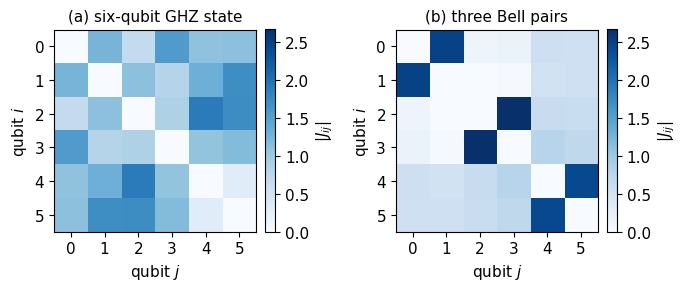

In [9]:
t_weights = time.perf_counter()
def effective_couplings(params):
    # equation (14): J = Re(w w^T), the coefficient of sigma_i sigma_j in the expansion of ln|Psi| to second order in the weights
    W = np.asarray(params["W"][0] + 1j * params["W"][1])
    J = np.abs(np.real(W @ W.T))
    np.fill_diagonal(J, 0.0)
    return J

PAIRS = [(0, 1), (2, 3), (4, 5)]
OTHER = [(i, j) for i in range(N) for j in range(i + 1, N) if (i, j) not in PAIRS]
COUPLINGS = {}
for name, fit in FIT.items():
    J_runs = [effective_couplings(select(fit["params"], 0, r)) for r in range(N_INIT)]          # network 0 is the unconstrained one
    COUPLINGS[name] = J_runs[int(GAPS[name]["best_run"][0])]
    print(f"{TITLE[name]}: for each of the {N_INIT} initialisations, smallest |J| on the pairs (0,1), (2,3), (4,5)"
          f" and largest |J| on the other twelve pairs")
    print("   " + "   ".join(f"{min(J[p] for p in PAIRS):.2f} / {max(J[p] for p in OTHER):.2f}" for J in J_runs))
    COUPLINGS[name + "_ratio"] = min(min(J[p] for p in PAIRS) / max(J[p] for p in OTHER) for J in J_runs)
print(f"smallest ratio of the two numbers over the initialisations: GHZ {COUPLINGS['GHZ_ratio']:.2f}, Bell pairs {COUPLINGS['Bell_ratio']:.2f}")
NUMBERS.update(CouplingRatioBell=f"{COUPLINGS['Bell_ratio']:.1f}")

def draw_couplings(name):
    def draw(ax, lab):
        image = ax.imshow(COUPLINGS[name], cmap="Blues", vmin=0, vmax=max(COUPLINGS["GHZ"].max(), COUPLINGS["Bell"].max()))
        ax.set_xticks(range(N)); ax.set_yticks(range(N)); ax.set_xlabel("qubit $j$"); ax.set_ylabel("qubit $i$")
        ax.set_title((lab + " " if lab else "") + TITLE[name], fontsize=11)
        plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label=r"$|J_{ij}|$")
    return draw
panels("fig_lab081_couplings", [draw_couplings("GHZ"), draw_couplings("Bell")], figsize=(7.0, 3.0))
time_weights = time.perf_counter() - t_weights
print(f"Section 9: {time_weights:.1f} s")

The panels show $|J_{ij}|$ for the best run of the unconstrained network, with the diagonal set to zero. For the three Bell pairs, panel (b), the three pairs stand out, and in all four initialisations the weakest coupling inside a pair is more than twice the strongest coupling between different pairs. For the GHZ state, panel (a), the couplings are spread over all pairs of qubits without a block pattern, and in every initialisation at least one of the three pairs is coupled more weakly than the strongest of the other twelve pairs. In this run the weights thus suggest the partition 2|2|2 for the Bell pairs before any cut network is trained. The matrix depends on the basis in which the amplitudes are written, and Ref. [1] reports that clusters in rotated local bases are less visible.

## 10. Mixed states under amplitude damping

This section is work for home and takes about 80 seconds. A real device prepares a mixed state. Following Ref. [1], we let every qubit decay from $|1\rangle$ to $|0\rangle$ with probability $p=0.05$. For one qubit this amplitude-damping channel has the Kraus operators $\hat E_0$ and $\hat E_1$,
$$\hat E_0=\begin{pmatrix}1&0\\0&\sqrt{1-p}\end{pmatrix},\qquad \hat E_1=\begin{pmatrix}0&\sqrt p\\0&0\end{pmatrix} , \tag{15}$$
and maps a state $\hat\rho$ to
$$\Lambda(\hat\rho)=\hat E_0\hat\rho\hat E_0^\dagger+\hat E_1\hat\rho\hat E_1^\dagger . \tag{16}$$
We apply it to all six qubits of the GHZ state and of the Bell pairs and simulate a new record of 100 settings with 400 shots from each damped state, with probabilities $p(\mathbf s\,|\,\mathbf q)=\langle\mathbf s|\hat U_{\mathbf q}\hat\rho\,\hat U_{\mathbf q}^\dagger|\mathbf s\rangle$, where $\hat U_{\mathbf q}$ is the product of the six rotations.

A single RBM is a pure state and cannot represent a statistical mixture. Ref. [1] therefore uses a statistical mixture of $R=4$ networks,
$$\hat\rho_\theta=\sum_{r=1}^{R}\mu_r\,|\Psi_{\theta_r}\rangle\langle\Psi_{\theta_r}|,\qquad \mu_r=\frac{e^{z_r}}{\sum_{r'}e^{z_{r'}}} , \tag{17}$$
with learned numbers $z_r$ that fix the probabilities $\mu_r$ of the components, and its probabilities are the weighted sums of the probabilities of the components. In the cut version every component carries the same mask, so $\hat\rho_\theta$ is a mixture of states that are products over the groups of the same partition $\mathcal P$. Such a mixture can hold classical correlations between the groups, as the mixture (6) does, and no entanglement across the cuts. A gap that survives then indicates entanglement across the cuts of $\mathcal P$. As in Ref. [1], the test covers one partition at a time, whereas the definition of Section 2 also allows mixtures of products over different partitions. The damped states have full rank, so four components are an approximation.

As a diagnostic of the fit we print the purity $\mathrm{Tr}\,\hat\rho^2$ of the damped state $\hat\rho$ and the Hilbert–Schmidt fidelity of Ref. [1] between $\hat\rho$ and the fitted mixture $\hat\rho_\theta$,
$$F_{\rm HS}=\frac{\mathrm{Tr}\big(\hat\rho\,\hat\rho_\theta\big)}{\sqrt{\mathrm{Tr}\,\hat\rho^2\;\mathrm{Tr}\,\hat\rho_\theta^2}} , \tag{18}$$
which equals one for identical states and needs the exact state, so it is available in a simulation only.

The cell trains the seven mixtures for 1000 Adam steps from three initialisations and applies the analysis of Section 7, with the threshold of Section 7. Its spread is taken over the three initialisations of the unconstrained mixture. A density matrix of rank $R$ in dimension $D$ has $2DR-R^2-1$ real parameters, so $n_{\rm eff}=495$ for $R=4$ and $D=64$, fewer than the 723 parameters of the four networks and their weights, and the shot-noise term equals $0.0062$. The output also lists, for every mixture, the loss of the exact state minus $\mathcal L^*$, a diagnostic that needs the exact state. For comparison it also trains the pure networks of Section 6 on the damped records. The last lines split the gap of the fully factorised mixture on the damped GHZ record into the contributions of the single settings. The published gaps of Ref. [1], Tables IV and V, are printed in a separate column and are no result of this notebook.


six-qubit GHZ state under amplitude damping, p = 0.05: purity 0.755, training 54 s
loss of the exact state 3.5747, best unconstrained ensemble 3.5735, best unconstrained pure network 3.6234; threshold 0.0109 = spread 0.0048 + shot noise 0.0062
      ensemble d_max      gap   spread  gap/threshold  exact - L*   F_HS      verdict  published gap [1]  gap, pure networks
 unconstrained     6   0.0000   0.0048            0.0      0.0012  0.997    reference                                  0.000
           1|5     5   0.0320   0.0021            2.9     -0.0309  0.716  disfavoured              0.026               0.408
           2|4     4   0.0354   0.0004            3.2     -0.0342  0.707  disfavoured              0.029               0.478
           3|3     3   0.0349   0.0023            3.2     -0.0338  0.709  disfavoured              0.029               0.486
         2|2|2     2   0.0339   0.0032            3.1     -0.0327  0.709  disfavoured              0.030               0.847
 2|2|

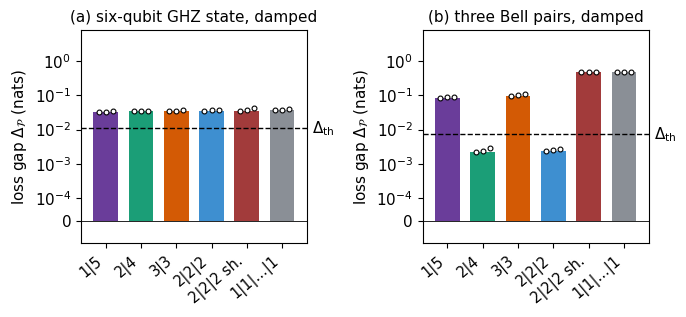

In [10]:
t_home = time.perf_counter()
P_DAMP, RANK = 0.05, 4
KRAUS = [np.array([[1, 0], [0, np.sqrt(1 - P_DAMP)]], complex), np.array([[0, np.sqrt(P_DAMP)], [0, 0]], complex)]   # equation (15)

def damp(rho):
    # equation (16) on every qubit in turn
    for q in range(N):
        ops = [kron_all([kraus if i == q else np.eye(2) for i in range(N)]) for kraus in KRAUS]
        rho = sum(op @ rho @ op.conj().T for op in ops)
    return rho

def record_mixed(rho, K, M, seed):
    rng = np.random.default_rng(seed)
    patterns = ["".join(rng.choice(list("XYZ"), size=N)) for _ in range(K)]
    U = np.array([kron_all([ROTATION[axis] for axis in pattern]) for pattern in patterns])
    exact = np.real(np.einsum("kxy,yz,kxz->kx", U, rho, U.conj()))        # diagonal of U rho U^dagger
    counts = measure(exact, M, rng)
    return dict(patterns=patterns, U1=jnp.asarray(pattern_unitaries(patterns)), exact=exact, counts=counts,
                L_exact=cross_entropy(counts, exact), rho=rho)

def init_ensemble(key):
    # RANK independent RBMs and one logit per component, equation (17)
    return dict(logit=jnp.zeros(RANK), rbm=jax.vmap(init_params)(jax.random.split(key, RANK)))

def ensemble_probabilities(params, mask, U1):
    w = jax.nn.softmax(params["logit"])
    p_components = jax.vmap(lambda prm: jnp.abs(rotate(amplitudes(prm, mask), U1)) ** 2)(params["rbm"])     # (RANK, K, 64)
    return jnp.einsum("r,rkx->kx", w, p_components)

def nll_ensemble(params, mask, U1, counts):
    return -jnp.sum(counts * jnp.log(ensemble_probabilities(params, mask, U1) + 1e-12)) / jnp.sum(counts)

def rho_ensemble(params, mask):
    w = np.asarray(jax.nn.softmax(params["logit"]))
    psis = np.asarray(jax.vmap(lambda prm: amplitudes(prm, mask))(params["rbm"]))
    return np.einsum("r,rx,ry->xy", w, psis, psis.conj())

def hs_fidelity(rho, sigma):
    # normalised Hilbert-Schmidt overlap, the diagnostic of Ref. [1]; needs the exact state
    return float(np.real(np.trace(rho @ sigma)) / np.sqrt(np.real(np.trace(rho @ rho)) * np.real(np.trace(sigma @ sigma))))

# published loss gaps of Ref. [1], Tables IV and V (amplitude damping with p = 0.05, ensembles of rank 4); typed in, not computed here
PUBLISHED_MIXED = {"GHZ": {"1|5": 0.026, "2|4": 0.029, "3|3": 0.029, "2|2|2": 0.030, "1|1|1|1|1|1": 0.030},
                   "Bell": {"1|5": 0.106, "2|4": 0.000, "3|3": 0.099, "2|2|2": 0.001, "1|1|1|1|1|1": 0.466}}

STEPS_MIXED, N_INIT_MIXED = 1000, 3
# a density matrix of rank R in dimension D has 2DR - R^2 - 1 real parameters, fewer than the real parameters of the R networks and weights
N_EFF_MIXED = min(RANK * n_real + RANK - 1, 2 * D * RANK - RANK ** 2 - 1)
train_mixed = make_trainer(nll_ensemble, STEPS_MIXED, LEARNING_RATE)
DATA_MIXED, FIT_MIXED, GAPS_MIXED = {}, {}, {}
for seed, (name, psi) in zip((8121, 8122), TARGETS.items()):
    d = record_mixed(damp(np.outer(psi, psi.conj())), K_PATTERNS, M_SHOTS, seed)
    counts = jnp.asarray(d["counts"], dtype=float)
    t0 = time.perf_counter()
    params, history, final = train_mixed(initial(init_ensemble, seed + 10, N_INIT_MIXED), MASKS, d["U1"], counts)
    g = analyse(np.asarray(final), N_EFF_MIXED)
    g["fidelity"] = np.array([hs_fidelity(d["rho"], rho_ensemble(select(params, i, int(g["best_run"][i])), MASKS[i])) for i in range(len(ARCH))])
    g["purity"] = float(np.real(np.trace(d["rho"] @ d["rho"])))
    g["bound"] = depth_bound(g["gap"], g["threshold"])
    g["overfit"] = d["L_exact"] - g["best"]          # needs the exact state: how far every mixture ends below the loss of the exact state
    # the pure-state networks of Section 6 on the same damped record
    _, _, final_pure = train_pure(initial(init_params, seed + 20, N_INIT), MASKS, d["U1"], counts)
    g["pure"] = analyse(np.asarray(final_pure), N_EFF_PURE)
    g["pure_minus_ensemble"] = float(g["pure"]["best"][0] - g["best"][0])
    DATA_MIXED[name], GAPS_MIXED[name] = d, g
    FIT_MIXED[name] = dict(params=params, final=np.asarray(final), seconds=time.perf_counter() - t0)
    print(f"\n{TITLE[name]} under amplitude damping, p = {P_DAMP}: purity {g['purity']:.3f}, training {FIT_MIXED[name]['seconds']:.0f} s")
    print(f"loss of the exact state {d['L_exact']:.4f}, best unconstrained ensemble {g['best'][0]:.4f},"
          f" best unconstrained pure network {g['pure']['best'][0]:.4f}; threshold {g['threshold']:.4f}"
          f" = spread {g['optimisation_term']:.4f} + shot noise {g['shot_term']:.4f}")
    print(f"{'ensemble':>14s} {'d_max':>5s} {'gap':>8s} {'spread':>8s} {'gap/threshold':>14s} {'exact - L*':>11s} {'F_HS':>6s}  {'verdict':>11s}"
          f" {'published gap [1]':>18s} {'gap, pure networks':>19s}")
    for i, arch in enumerate(ARCH):
        pub = f"{PUBLISHED_MIXED[name][arch]:.3f}" if arch in PUBLISHED_MIXED[name] else ""
        print(f"{LABEL[arch]:>14s} {D_MAX[arch]:5d} {g['gap'][i]:8.4f} {g['spread'][i]:8.4f} {g['gap'][i] / g['threshold']:14.1f} {g['overfit'][i]:11.4f}"
              f" {g['fidelity'][i]:6.3f}  "
              f"{verdict(arch, g['gap'][i], g['threshold']):>11s} {pub:>18s} {g['pure']['gap'][i]:19.3f}")
    compatible = [LABEL[a] for i, a in enumerate(ARCH) if a != "full" and g["gap"][i] <= g["threshold"]]
    print(f"criterion (13) with this threshold returns depth > {g['bound']} within the tested ensembles; masked ensembles below the threshold:"
          f" {compatible or 'none'}")
    for i, arch in enumerate(ARCH[1:], start=1):
        NUMBERS[f"DampedGap{name}{KEY[arch]}"] = number(g["gap"][i])
    NUMBERS[f"DampedPurity{name}"] = f"{g['purity']:.3f}"
    NUMBERS[f"DampedThreshold{name}"] = number(g["threshold"])
    NUMBERS[f"DampedBound{name}"] = f"{g['bound']}"
    NUMBERS[f"DampedPureMinusEnsemble{name}"] = number(g["pure_minus_ensemble"])
    NUMBERS[f"DampedFidelityFull{name}"] = f"{g['fidelity'][0]:.3f}"
    NUMBERS[f"DampedLargestMaskedSpread{name}"] = number(g["largest_masked_spread"])    # the threshold of the earlier rule
    NUMBERS[f"DampedSmallestExcludedRatio{name}"] = f"{min(excluded(g)) / g['threshold']:.1f}"
    NUMBERS[f"DampedShotTerm{name}"] = number(g["shot_term"])
    NUMBERS[f"DampedLargestCompatibleRatio{name}"] = f"{max([x / g['threshold'] for x in g['gap'][1:] if x <= g['threshold']], default=0.0):.2f}"
    NUMBERS[f"DampedOverfitFull{name}"] = number(float(g["overfit"][0]))

NUMBERS.update(NEffMixed=f"{N_EFF_MIXED}")

# where the gap of the damped GHZ record comes from: contribution of every pattern to the gap of the product ensemble
d, g, params = DATA_MIXED["GHZ"], GAPS_MIXED["GHZ"], FIT_MIXED["GHZ"]["params"]
def loss_per_pattern(i):
    p = np.asarray(ensemble_probabilities(select(params, i, int(g["best_run"][i])), MASKS[i], d["U1"]))
    return -np.sum(d["counts"] * np.log(p + 1e-12), axis=1) / d["counts"].sum()
contribution = loss_per_pattern(len(ARCH) - 1) - loss_per_pattern(0)
is_coherence = np.array([p in coherence_patterns(d["patterns"]) for p in d["patterns"]])
share = float(contribution[is_coherence].sum() / contribution.sum())
print(f"\ndamped GHZ record: {int(is_coherence.sum())} of {K_PATTERNS} patterns have no Z and an even number of Y; they carry"
      f" {contribution[is_coherence].sum():.4f} of the gap {contribution.sum():.4f} of the product ensemble ({100 * share:.0f} per cent)")
NUMBERS.update(DampedCoherencePatterns=f"{int(is_coherence.sum())}", DampedCoherenceShare=f"{100 * share:.0f}")

panels("fig_lab081_gaps_damped", [draw_gaps(GAPS_MIXED, N_INIT_MIXED, ", damped")("GHZ"), draw_gaps(GAPS_MIXED, N_INIT_MIXED, ", damped")("Bell")],
       figsize=(7.0, 3.3))
time_home = time.perf_counter() - t_home
print(f"Section 10: {time_home:.0f} s")

The damped states have a purity of $0.755$ and $0.747$. A pure network cannot follow them, and the best unconstrained pure network ends $0.050$ and $0.035$ nats above the unconstrained mixture. The unconstrained mixture reaches a Hilbert–Schmidt fidelity of $0.997$ and $0.995$ with the damped state, so four components describe both states well. The table collects the gaps of the cut mixtures next to the published ones of Ref. [1].

| mixture | GHZ, this notebook | GHZ, Ref. [1] | Bell pairs, this notebook | Bell pairs, Ref. [1] |
|---|---|---|---|---|
| 1&#124;5 | $0.032$ | $0.026$ | $0.085$ | $0.106$ |
| 2&#124;4 | $0.035$ | $0.029$ | $0.002$ | $0.000$ |
| 3&#124;3 | $0.035$ | $0.029$ | $0.099$ | $0.099$ |
| 2&#124;2&#124;2 | $0.034$ | $0.030$ | $0.002$ | $0.001$ |
| 2&#124;2&#124;2 shifted | $0.034$ | | $0.47$ | |
| 1&#124;1&#124;1&#124;1&#124;1&#124;1 | $0.038$ | $0.030$ | $0.47$ | $0.466$ |
| spread $s_{\rm full}$ | $0.0048$ | | $0.0010$ | |
| threshold $\Delta_{\rm th}$ | $0.011$ | | $0.0072$ | |

For the damped GHZ record, panel (a), all six cut mixtures have gaps of about three times the threshold, so criterion (13) returns $d_e>5$ within the tested mixtures of rank four. The gaps are more than ten times smaller than those of the pure networks on the same record, which lie between $0.41$ and $1.69$. The difference is the part of the pure-state gaps that came from classical correlations, which a mixture reproduces. The remaining gap comes from few settings, since the seven settings without $z$ and with an even number of $y$ carry 82 per cent of the gap of the fully factorised mixture. The certificate for the GHZ state thus rests on seven of the 100 settings of this record. A record without such a setting is reproduced equally well by the damped mixture (6), which contains no entanglement, and cannot certify the depth.

For the damped Bell pairs, panel (b), the four partitions that cut a pair have gaps of more than eleven times the threshold. The mixtures 2|2|2 and 2|4 have gaps of $0.0024$ and $0.0022$, about a third of the threshold, so they count as compatible and criterion (13) returns $d_e>1$, in agreement with a depth of two. These two gaps are shot noise. The column `exact - L*` of the output shows that the unconstrained mixture ends $0.0024$ nats below the loss of the exact state, because it fits the fluctuations of the 40 000 outcomes, whereas the two cut mixtures have fewer weights and end within $0.0003$ nats of the loss of the exact state. The spread alone, $0.0010$, is smaller than both gaps and would exclude these two true partitions, which would give the false bound $d_e>5$. The shot-noise term prevents this error. Ref. [1] uses ten times more outcomes, for which this effect per shot is smaller, and reports gaps of $0.000$ and $0.001$ for these two partitions.

Our gaps agree with those of Ref. [1] within about $0.02$. Every statement of this section comes from one record per state and three initialisations, and a spread taken from three runs is itself uncertain, as the values $0.0048$ and $0.0010$ for the same model on two similar records show. The gaps of the damped GHZ state lie only about three times above the threshold, so the margin of the bound $d_e>5$ is modest.

The last cell writes the numbers quoted in the text to `classroom_results/lab081_results.json` and to the macro file `figures/nb_numbers_lab081.tex`.

In [11]:
def as_list(x):
    return [float(v) for v in np.asarray(x).ravel()]

def block(g, final):
    return dict(final_loss={a: as_list(final[i]) for i, a in enumerate(ARCH)}, gap={a: float(g["gap"][i]) for i, a in enumerate(ARCH)},
                spread={a: float(g["spread"][i]) for i, a in enumerate(ARCH)}, threshold=g["threshold"],
                threshold_optimisation_term=g["optimisation_term"], threshold_shot_noise_term=g["shot_term"], effective_parameters=g["n_eff"],
                largest_spread_of_a_masked_network=g["largest_masked_spread"], depth_bound=g["bound"],
                fidelity_best_run={a: float(g["fidelity"][i]) for i, a in enumerate(ARCH)})

summary = dict(
    experiment="entanglement depth from masked RBM wave functions: six qubits, random local Pauli patterns, exact Born probabilities "
               "of the network, negative log-likelihood minimised with Adam; JAX float64 on CPU; one record per state",
    settings=dict(patterns=K_PATTERNS, shots_per_pattern=M_SHOTS, hidden_units=N_HIDDEN, real_parameters=n_real, steps=STEPS,
                  learning_rate=LEARNING_RATE, initialisations=N_INIT, partitions=PARTITIONS, d_max=D_MAX,
                  threshold_rule="spread (largest minus smallest) of the final loss of the unconstrained network over its initialisations "
                                 "plus n_eff / (2 * total shots), with n_eff the real parameters of the states the unconstrained model can represent; "
                                 "the optimum of every network is its smallest final loss over the initialisations"),
    pure={name: dict(patterns=DATA[name]["patterns"], loss_exact_state=DATA[name]["L_exact"], exact_minus_unconstrained=GAPS[name]["overfit"],
                     train_seconds=FIT[name]["seconds"], **block(GAPS[name], FIT[name]["final"])) for name in FIT},
    couplings=dict(smallest_ratio_pairs_to_others={name: float(COUPLINGS[name + "_ratio"]) for name in FIT},
                   best_run={name: COUPLINGS[name].tolist() for name in FIT}),
    damped={name: dict(p=P_DAMP, rank=RANK, steps=STEPS_MIXED, initialisations=N_INIT_MIXED, purity=GAPS_MIXED[name]["purity"],
                       loss_exact_state=DATA_MIXED[name]["L_exact"], pure_network_minus_ensemble=GAPS_MIXED[name]["pure_minus_ensemble"],
                       gap_pure_networks={a: float(GAPS_MIXED[name]["pure"]["gap"][i]) for i, a in enumerate(ARCH)},
                       exact_minus_best_loss={a: float(GAPS_MIXED[name]["overfit"][i]) for i, a in enumerate(ARCH)},
                       train_seconds=FIT_MIXED[name]["seconds"], **block(GAPS_MIXED[name], FIT_MIXED[name]["final"])) for name in FIT_MIXED},
    damped_ghz_share_of_gap_from_coherence_patterns=share,
    published_ref1=dict(pure_gap=PUBLISHED, damped_gap=PUBLISHED_MIXED,
                        note="Ref. [1], Tables I, II, IV and V; 200 patterns x 2000 shots, 64 + 64 hidden units, 6000 Adam steps; not simulated here"),
    runtime_seconds=dict(core_sections_1_8=time_core, at_home_section_9=time_weights, at_home_section_10=time_home,
                         total=time.perf_counter() - started))
NUMBERS.update(RuntimeCore=f"{time_core:.0f}", RuntimeHome=f"{time_home:.0f}")
with open(RES / "lab081_results.json", "w") as f:
    json.dump(summary, f, indent=1)
with open(FIG / "nb_numbers_lab081.tex", "w") as f:
    f.write("% numbers of Lab 081, written by the notebook; our results, not the values of Ref. [1]\n")
    for k_, v_ in NUMBERS.items():
        f.write(f"\\newcommand{{\\labeightyone{k_}}}{{{v_.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime: Sections 1-8 {time_core:.1f} s, Section 9 {time_weights:.1f} s, Section 10 {time_home:.1f} s,"
      f" total {summary['runtime_seconds']['total']:.1f} s")

numbers: {'CoherencePatternsOfAll': '32', 'Patterns': '100', 'ShotsPerPattern': '400', 'ShotsTotal': '40000', 'GhzCoherencePatterns': '2', 'LossExactGHZ': '3.272', 'LossExactBell': '3.507', 'Hidden': '12', 'Parameters': '180', 'LossUntrained': '8.14', 'FactorisationError': '6e-16', 'OwnCutEntropy': '2e-15', 'Steps': '600', 'Inits': '4', 'GapGHZOneFive': '0.41', 'GapGHZTwoFour': '0.49', 'GapGHZThreeThree': '0.56', 'GapGHZTwoTwoTwo': '0.96', 'GapGHZShifted': '1.03', 'GapGHZProduct': '2.06', 'BoundGHZ': '5', 'ThresholdGHZ': '0.0016', 'SpreadFullGHZ': '0.00004', 'OverfitGHZ': '0.00006', 'FidelityFullGHZ': '0.9996', 'SmallestExcludedGapGHZ': '0.41', 'LargestMaskedSpreadGHZ': '0.025', 'SmallestExcludedRatioGHZ': '252', 'ShotTermGHZ': '0.0016', 'LargestCompatibleRatioGHZ': '0.00', 'GapBellOneFive': '0.66', 'GapBellTwoFour': '0.0001', 'GapBellThreeThree': '0.55', 'GapBellTwoTwoTwo': '0.0002', 'GapBellShifted': '1.23', 'GapBellProduct': '1.84', 'BoundBell': '1', 'ThresholdBell': '0.0018', 'Spre

## 11. Summary

An RBM wave function whose weights are cut according to a partition of the qubits is a product state over the groups of the partition, which we confirmed numerically through an entanglement entropy (4) that vanishes to numerical precision across the cuts. The four-amplitude test of the lecture gives the same verdict on the two targets. Fitting cut and unconstrained networks to the same record of random Pauli measurements turns the question about entanglement depth into a comparison of negative log-likelihoods.

On a simulated record of 100 settings with 400 shots each, the unconstrained network reached the loss of the exact state for both targets. For the six-qubit GHZ state all six cut networks were disfavoured, with gaps between $0.41$ and $2.06$ nats per shot against a threshold of $1.6\times10^{-3}$, which gives $d_e>5$, a depth of six, within pure states and the tested partitions. For three Bell pairs the partition into the true pairs and the coarser partition 2|4 fitted as well as the unconstrained network, with gaps of at most $0.13$ of the threshold of $1.8\times10^{-3}$, while the product network, the partitions 1|5 and 3|3 and the shifted pairs had gaps between $0.55$ and $1.84$. The bound is $d_e>1$, and a model of depth two explains the record. The gaps agree with the published ones of Ref. [1] within $0.09$.

At home, the effective couplings computed from the weights of the unconstrained network showed the three Bell pairs in all four initialisations. With mixtures of four networks the cut mixtures had gaps of about $0.035$ on the record of the damped GHZ state, three times the threshold, and for the fully factorised mixture 82 per cent of this gap came from seven of the 100 settings. On the record of the damped Bell pairs the two fitting partitions had gaps of about a third of the threshold, and the criterion returned the correct bound $d_e>1$. These gaps were shot noise fitted by the unconstrained mixture, and the spread of the optimisation alone would have excluded both partitions wrongly.

These results come from one simulated record per state. The threshold is a rule of this notebook, the spread of the unconstrained network over a few initialisations plus an estimate of the loss gained by fitting shot noise, only six of the 203 partitions of six qubits were tested, and an exclusion holds for the states that the cut networks can represent and reach in training.


## 12. Exercises

1. Starting from equations (7) and (10), write the two factors $\tilde\psi_1(s_0,s_1,s_2)$ and $\tilde\psi_2(s_3,s_4,s_5)$ of equation (11) for the partition 3|3, and state which biases and weights each of them contains.
2. Show that the expectation value of $\hat\sigma^x_0\hat\sigma^x_1\cdots\hat\sigma^x_5$ is $+1$ in the GHZ state and $0$ in the mixture (6), and explain with this result why half of the outcomes are absent in panel (b) of the figure of Section 3. Then compute the expected number of settings without $z$ and with an even number of $y$ among 100 random settings.
3. Add the partitions $\{0,1,2,3\},\{4,5\}$ and $\{0,2\},\{1,3\},\{4,5\}$ to `PARTITIONS`. Predict for the three Bell pairs which of the two gaps vanishes, then rerun Sections 5 to 7 and compare.
4. Replace the GHZ state by the six-qubit W state, the equal superposition of the six bit strings with a single 1, and determine the bound on its depth from criterion (13). Compare the gaps with those of the GHZ state.
5. Repeat Sections 3 to 7 with $n_{\rm s}=50$ shots per setting. Report how the gaps of the networks 2|2|2 and 2|4 on the Bell record, the difference between the loss of the exact state and $\mathcal L^*_{\rm full}$, and the threshold change.

## References

[1] M. Płodzień, Neural quantum states for entanglement-depth certification from randomized Pauli measurements, Phys. Rev. Research **8**, 023255 (2026), doi:[10.1103/29hj-7w41](https://doi.org/10.1103/29hj-7w41).

[2] O. Gühne and G. Tóth, Entanglement detection, Phys. Rep. **474**, 1 (2009), doi:[10.1016/j.physrep.2009.02.004](https://doi.org/10.1016/j.physrep.2009.02.004).

[3] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:[10.1126/science.aag2302](https://doi.org/10.1126/science.aag2302).

[4] G. Torlai, G. Mazzola, J. Carrasquilla, M. Troyer, R. Melko and G. Carleo, Neural-network quantum state tomography, Nat. Phys. **14**, 447 (2018), doi:[10.1038/s41567-018-0048-5](https://doi.org/10.1038/s41567-018-0048-5).

[5] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980).

[6] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[7] S. S. Wilks, The large-sample distribution of the likelihood ratio for testing composite hypotheses, Ann. Math. Stat. **9**, 60 (1938), doi:[10.1214/aoms/1177732360](https://doi.org/10.1214/aoms/1177732360).
